# Southeast Asian teams at FIFA Women's World Cup

How did Southeast Asian teams perfrom at FIFA Women's World Cup in 2019 and 2023?

## Import libraries

In [1]:
import os, sys
import importlib

import pandas as pd 
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from mplsoccer import Pitch, VerticalPitch

from statsbombpy import sb 

import functions

sys.path.insert(0, os.path.dirname(functions.__file__))

importlib.reload(functions)

from functions import (side_view, build_match_time_anchors, add_elapsed_time, build_state_intervals, display_minute, 
                       build_formation_timeline, build_final_stints, minutes_by_state, table_before, table_string, result_row, 
                       placing, opponent_context, add_labels, in_own_half, in_own_third, in_final_third, is_long_pass, in_own_box, 
                       in_opposition_box, distance_to_goal, distance, is_left_side, is_right_side, is_central, xg_timeline, 
                       plot_xg_timeline, plot_team_timelines, split_at_minute, first_goal_rates, shot_table, shot_profile, 
                       score_from_timeline, own_goal_counts, penalty_line, plot_team_shot_maps, add_shot_origin, origin_summary, 
                       origin_table, possession_table, _loss_cause, ball_losses, add_next_possession_shots, loss_summary, plot_loss_map,
                       loss_key, plot_team_loss_maps, add_won_location, ball_regains, add_regain_outcome, regain_summary,
                       defending_profile, plot_regain_map, regain_key, plot_team_regain_maps,
                       team_colors, tabs, tab_names, plots_dir,
                       scorer_lines, add_header_lines,
                       plot_stat_comparison, draw_match_header, tab_footer, plot_stats_tab,
                       folder_name, match_folder, overall_folder, save_figure, save_tab,
                       merge_state_spells, plot_xg_race_tab, state_colors, state_labels,
                       origin_breakdown, plot_origin_comparison, track, plot_shots_tab,
                       minute_label, build_goal_ledger, plot_goals_tab, category_colors, flag_columns,
                       plot_losses_tab, plot_regains_tab, plot_build_up_tab,
                       _channel_pitch, plot_attack_tab,
                       plot_possessions_tab, plot_possession_funnel, plot_end_type_bars, funnel_rows, end_type_order, end_type_colors,
                       plot_game_state_tab, plot_state_table, plot_state_strip, _dot_legend, state_order, before_color, after_color,
                       plot_home_tab, save_match_pdf, tab_blurbs)

In [2]:
if os.path.basename(os.getcwd()) == 'code':
    os.chdir('..')

In [3]:
print(os.getcwd())

e:\GitHub\SEA-Teams-FWWC


## Data preparation

### Check competition information

In [4]:
competitions = sb.competitions()

In [5]:
competitions

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
0,9,281,Germany,1. Bundesliga,male,False,False,2023/2024,2024-09-28T20:46:38.893391,2025-11-15T23:17:41.827093,2025-11-15T23:17:41.827093,2024-09-28T20:46:38.893391
1,9,27,Germany,1. Bundesliga,male,False,False,2015/2016,2024-05-19T11:11:14.192381,NaN,NaN,2024-05-19T11:11:14.192381
2,1267,107,Africa,African Cup of Nations,male,False,True,2023,2026-05-12T21:18:08.827431,2026-05-02T02:07:18.902396,2026-05-02T02:07:18.902396,2026-05-12T21:18:08.827431
3,16,4,Europe,Champions League,male,False,False,2018/2019,2026-05-15T15:54:04.598614,2021-06-13T16:17:31.694,NaN,2026-05-15T15:54:04.598614
4,16,1,Europe,Champions League,male,False,False,2017/2018,2024-02-13T02:35:28.134882,2021-06-13T16:17:31.694,NaN,2024-02-13T02:35:28.134882
...,...,...,...,...,...,...,...,...,...,...,...,...
75,35,75,Europe,UEFA Europa League,male,False,False,1988/1989,2026-04-11T12:48:10.012987,2021-06-13T16:17:31.694,NaN,2026-04-11T12:48:10.012987
76,53,315,Europe,UEFA Women's Euro,female,False,True,2025,2026-04-27T22:02:42.690507,2026-04-27T22:03:28.087062,2026-04-27T22:03:28.087062,2026-04-27T22:02:42.690507
77,53,106,Europe,UEFA Women's Euro,female,False,True,2022,2026-05-05T03:03:04.199896,2026-05-05T03:05:32.480837,2026-05-05T03:05:32.480837,2026-05-05T03:03:04.199896
78,72,107,International,Women's World Cup,female,False,True,2023,2026-05-03T13:51:31.021141,2026-05-03T13:55:52.303219,2026-05-03T13:55:52.303219,2026-05-03T13:51:31.021141


### Teams id lookup

In [6]:
tournaments = {"WWC 2019": (72, 30), "WWC 2023": (72, 107)}

In [7]:
teams_sea = {1107: "Thailand W", 16769: "Vietnam Women\'s", 1106: "Philippines Women\'s"}

In [8]:
countrys_sea = {226: "Thailand", 247: "Vietnam", 180: "Philippines"}

### All matches

In [9]:
frames = []

In [10]:
for name, (comp_id, season_id) in tournaments.items():
    m = sb.matches(competition_id=comp_id, season_id=season_id)
    frames.append(m)

In [11]:
matches_raw = pd.concat(frames, ignore_index=True)

In [12]:
matches_raw = matches_raw.sort_values(by=['match_date', 'kick_off'])

In [13]:
matches_raw

,match_id,match_date,kick_off,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,match_week,...,home_manager_country_name,away_manager_id,away_manager_name,away_manager_nickname,away_manager_dob,away_manager_country_id,away_manager_country_name,data_version,shot_fidelity_version,xy_fidelity_version
43,22921,2019-06-07,19:00:00.000,4,0,available,scheduled,2025-09-10T22:38:18.033068,2021-06-13T16:17:31.694,1,...,France,4300,Deuk-Yeo Yoon,Yoon Deuk-Yeo,1961-03-25,121,Korea (South),1.1.0,2,2
32,22926,2019-06-08,13:00:00.000,1,0,available,scheduled,2026-05-15T15:21:36.184896,2021-06-13T16:17:31.694,1,...,Germany,3955,Xiuquan Jia,Jia Xiuquan,1963-11-09,46,China,1.1.0,2,2
44,22930,2019-06-08,16:00:00.000,3,1,available,scheduled,2026-05-15T15:19:39.803771,2021-06-13T16:17:31.694,1,...,Spain,3925,Desiree Ellis,NaN,1963-03-14,211,South Africa,1.1.0,2,2
42,22924,2019-06-08,19:00:00.000,3,0,available,scheduled,2026-05-15T15:20:38.687207,2021-06-13T16:17:31.694,1,...,Sweden,4553,Thomas Dennerby,NaN,1959-08-13,220,Sweden,1.1.0,2,2
34,22933,2019-06-09,11:00:00.000,1,2,available,scheduled,2025-09-10T22:43:05.160820,2021-06-13T16:17:31.694,1,...,Australia,4085,Milena Bertolini,NaN,1966-06-24,112,Italy,1.1.0,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,3902967,2023-08-12,10:30:00.000,2,1,available,available,2026-05-02T13:53:19.273716,2026-05-02T13:54:22.212332,5,...,Netherlands,1003448,Nelson Abadía Aragón,NaN,1956-06-05,49,Colombia,1.1.0,2,2
93,3904628,2023-08-15,08:00:00.000,2,1,available,available,2026-05-02T13:54:26.006834,2026-05-02T13:56:54.575146,6,...,Spain,3016,Peter Gerhardsson,NaN,1959-08-22,220,Sweden,1.1.0,2,2
90,3904629,2023-08-16,13:00:00.000,1,3,available,available,2024-05-23T08:35:51.665229,2024-05-23T08:38:03.731618,6,...,Sweden,45,Sarina Glotzbach-Wiegman,Sarina Wiegman,1969-10-26,160,Netherlands,1.1.0,2,2
91,3906389,2023-08-19,11:00:00.000,2,0,available,available,2024-02-13T14:14:42.021817,2024-02-13T14:19:12.386420,7,...,Sweden,408,Tony Gustavsson,NaN,1973-08-14,220,Sweden,1.1.0,2,2


### One row per team per match

In [14]:
long = pd.concat([side_view(matches_raw, "home", "away"),
                  side_view(matches_raw, "away", "home")])

In [15]:
matches_sea = long[long["team_id"].isin(teams_sea)].copy()

In [16]:
matches_sea = matches_sea.sort_values(by=['season_id', 'team_id', 'match_week'])

In [17]:
matches_sea

,match_id,competition_id,competition_name,season_id,season,match_week,match_date,kick_off,competition_stage_id,competition_stage,team_id,team,manager_id,manager_name,opponent_id,opponent,stadium_country_id,stadium_country_name,goals_for,goals_against
15,22943,72,Women's World Cup,30,2019,1,2019-06-11,19:00:00.000,10,Group Stage,1107,Thailand W,4390,Nuengrutai Srathongvian,1214,United States Women's,78,France,0,13
9,22973,72,Women's World Cup,30,2019,2,2019-06-16,13:00:00.000,10,Group Stage,1107,Thailand W,4390,Nuengrutai Srathongvian,858,Sweden Women's,78,France,1,5
17,68343,72,Women's World Cup,30,2019,3,2019-06-20,19:00:00.000,10,Group Stage,1107,Thailand W,4390,Nuengrutai Srathongvian,1209,Chile Women's,78,France,0,2
111,3893789,72,Women's World Cup,107,2023,1,2023-07-21,05:00:00.000,10,Group Stage,1106,Philippines Women's,2957,Alen Stajčić,860,Switzerland Women's,163,New Zealand,0,2
115,3893803,72,Women's World Cup,107,2023,2,2023-07-25,08:30:00.000,10,Group Stage,1106,Philippines Women's,2957,Alen Stajčić,1215,New Zealand Women's,14,Australia,1,0
88,3893820,72,Women's World Cup,107,2023,3,2023-07-30,07:00:00.000,10,Group Stage,1106,Philippines Women's,2957,Alen Stajčić,852,Norway Women's,163,New Zealand,0,6
113,3893792,72,Women's World Cup,107,2023,1,2023-07-22,01:00:00.000,10,Group Stage,16769,Vietnam Women's,1003426,Đức Chung Mai,1214,United States Women's,163,New Zealand,0,3
86,3893810,72,Women's World Cup,107,2023,2,2023-07-27,07:30:00.000,10,Group Stage,16769,Vietnam Women's,1003426,Đức Chung Mai,864,Portugal Women's,163,New Zealand,0,2
65,3893827,72,Women's World Cup,107,2023,3,2023-08-01,07:00:00.000,10,Group Stage,16769,Vietnam Women's,1003426,Đức Chung Mai,851,Netherlands Women's,163,New Zealand,0,7


In [18]:
opponent_map = pd.concat([
    matches_sea[["match_id", "team_id", "opponent_id"]],
    matches_sea[["match_id", "opponent_id", "team_id"]]
        .rename(columns={"opponent_id": "team_id", "team_id": "opponent_id"}),
], ignore_index=True)

### Import match events

In [19]:
events_matches_sea = pd.concat(
    [sb.events(match_id=mid) for mid in matches_sea['match_id']],
    ignore_index=True,
)

In [20]:
events_matches_sea = events_matches_sea.sort_values(["match_id", "index"]).reset_index(drop=True)

In [21]:
events_matches_sea.shape

(31260, 110)

### Extract location columns

In [22]:
location_cols = events_matches_sea.filter(like='location').columns.tolist()

In [23]:
for col in location_cols:
    parsed = events_matches_sea[col]

    events_matches_sea[f'{col}_x'] = parsed.str[0]
    events_matches_sea[f'{col}_y'] = parsed.str[1]

    max_len = parsed.str.len().max()
    if pd.notna(max_len) and max_len > 2:
        events_matches_sea[f'{col}_z'] = parsed.str[2]
        print(f"{col}: created x, y, z")
    else:
        print(f"{col}: created x, y only")

carry_end_location: created x, y only
goalkeeper_end_location: created x, y only
location: created x, y only
pass_end_location: created x, y only
shot_end_location: created x, y, z


In [24]:
events_matches_sea['under_pressure'] = events_matches_sea['under_pressure'].fillna(False).astype(bool)

In [25]:
events_matches_sea['is_sea'] = events_matches_sea['team_id'].isin(teams_sea)

### Mapping

In [26]:
team_names = dict(zip(matches_raw["home_team_id"], matches_raw["home_team"]))
team_names.update(zip(matches_raw["away_team_id"], matches_raw["away_team"]))

In [27]:
player_names = (events_matches_sea.dropna(subset=['player_id'])
                .astype({'player_id': int})
                .groupby('player_id')['player'].last()                  # most recent spelling
                .to_dict())

In [28]:
competition_names = dict(zip(matches_raw['competition_id'], matches_raw['competition_name']))

In [29]:
season_names = dict(zip(matches_raw['season_id'], matches_raw['season']))

In [30]:
events_matches_sea = events_matches_sea.merge(matches_sea[['match_id', 'competition_id', 'season_id']], on='match_id', how='left', validate='m:1')

In [31]:
labels = matches_sea[["match_id", "match_week", "team_id", "opponent_id"]].assign(
    team=lambda d: d["team_id"].map(team_names),
    opponent=lambda d: d["opponent_id"].map(team_names),
)

### Time frame

In [32]:
period_end, half_time, match_end, period_offset = build_match_time_anchors([events_matches_sea])

In [33]:
events_matches_sea = add_elapsed_time(events_matches_sea, period_offset)

In [34]:
matches_sea["match_length"] = matches_sea["match_id"].map(match_end)

### Score timeline and game state

#### Filter goals

In [35]:
is_goal = (((events_matches_sea["type"] == "Shot") & (events_matches_sea["shot_outcome"] == "Goal"))
           | (events_matches_sea["type"] == "Own Goal For"))          # Own Goal For sits on the benefiting team

In [36]:
events_matches_sea['is_penalty'] = events_matches_sea["shot_type"] == "Penalty"

In [37]:
events_matches_sea['np_shot_statsbomb_xg'] = events_matches_sea['shot_statsbomb_xg'] * ~events_matches_sea['is_penalty']

In [38]:
events_matches_sea['goal_for'] = is_goal & events_matches_sea['is_sea']

In [39]:
events_matches_sea['goal_against'] = is_goal & ~events_matches_sea['is_sea']

In [40]:
g = events_matches_sea.groupby("match_id")

In [41]:
events_matches_sea['score_for'] = g['goal_for'].cumsum() - events_matches_sea['goal_for']   # score BEFORE the event

In [42]:
events_matches_sea['score_against'] = g['goal_against'].cumsum() - events_matches_sea['goal_against']

#### Difference and game state

In [43]:
diff = events_matches_sea['score_for'] - events_matches_sea['score_against']

In [44]:
events_matches_sea["game_state"] = np.select(
    [diff > 0, diff == 0, diff == -1, diff == -2],
    ["leading", "level", "trailing by 1", "trailing by 2"],
    "trailing by 3+",
)

#### Goal information

In [45]:
goals = events_matches_sea.loc[
    events_matches_sea["goal_for"] | events_matches_sea["goal_against"],
    ["match_id", "competition_id", "season_id", "id", "elapsed_min", "period", "minute",
     "team", "player", "player_id", "type", "shot_type", "goal_for"],
].sort_values(["match_id", "elapsed_min"]).copy()

In [46]:
goals["display"] = [display_minute(p, m) for p, m in zip(goals["period"], goals["minute"])]

In [47]:
goals.loc[goals["shot_type"] == "Penalty", "display"] += " (pen)"

In [48]:
is_og = goals["type"] == "Own Goal For"

In [49]:
goals.loc[is_og, "display"] += " (og)"

In [50]:
oga = events_matches_sea[events_matches_sea["type"] == "Own Goal Against"]

In [51]:
og_scorer = {rel: name for rels, name in zip(oga["related_events"], oga["player"]) for rel in rels}

In [52]:
goals["scorer"] = goals["player"]

In [53]:
goals.loc[is_og, "scorer"] = goals.loc[is_og, "id"].map(og_scorer)

In [54]:
scorers = (
    goals.groupby(["match_id", "goal_for", "scorer"], sort=False)
    .agg(first=("elapsed_min", "min"), mins=("display", ", ".join))
    .reset_index()
    .sort_values(["match_id", "first"])
)

In [55]:
scorers["txt"] = scorers["scorer"] + " " + scorers["mins"]

In [56]:
scorer_str = (
    scorers.groupby(["match_id", "goal_for"])["txt"].agg("; ".join)
    .unstack()
    .rename(columns={True: "sea_scorers", False: "opp_scorers"})
    .reset_index()
)

In [57]:
scorer_str.columns.name = None

In [58]:
third = (
    goals[~goals["goal_for"]].groupby("match_id").nth(2)[["match_id", "display", "elapsed_min"]]
    .rename(columns={"display": "third_conceded", "elapsed_min": "third_conceded_elapsed"})
)

In [59]:
matches_sea = (
    matches_sea
    .merge(scorer_str, on="match_id", how="left", validate="one_to_one")
    .merge(third, on="match_id", how="left", validate="one_to_one")
)

In [60]:
matches_sea[["sea_scorers", "opp_scorers"]] = matches_sea[["sea_scorers", "opp_scorers"]].fillna("–")

#### Score after each goal

In [61]:
goals['score_for'] = events_matches_sea.loc[goals.index, 'score_for'] + goals['goal_for']    # score AFTER the goal

In [62]:
goals['score_against'] = events_matches_sea.loc[goals.index, 'score_against'] + ~goals['goal_for']

#### Build state intervals

In [63]:
state_intervals = build_state_intervals(goals, match_end)

#### Goals by half

In [64]:
ht = (
    events_matches_sea[events_matches_sea["period"] == 1]
    .groupby("match_id")[["goal_for", "goal_against"]]
    .sum()
    .rename(columns={"goal_for": "goals_for_h1", "goal_against": "goals_against_h1"})
    .reset_index()
)

In [65]:
matches_sea = matches_sea.merge(ht, on="match_id", how="left", validate="1:1")

In [66]:
matches_sea["goals_for_h2"] = matches_sea["goals_for"] - matches_sea["goals_for_h1"]

In [67]:
matches_sea["goals_against_h2"] = matches_sea["goals_against"] - matches_sea["goals_against_h1"]

#### Table check

In [68]:
matches_sea

,match_id,competition_id,competition_name,season_id,season,match_week,match_date,kick_off,competition_stage_id,competition_stage,...,goals_against,match_length,opp_scorers,sea_scorers,third_conceded,third_conceded_elapsed,goals_for_h1,goals_against_h1,goals_for_h2,goals_against_h2
0,22943,72,Women's World Cup,30,2019,1,2019-06-11,19:00:00.000,10,Group Stage,...,13,95.383333,"Alexandra Morgan Carrasco 12', 53', 74', 81', ...",–,32',31.233333,0,3,0,10
1,22973,72,Women's World Cup,30,2019,2,2019-06-16,13:00:00.000,10,Group Stage,...,5,96.633333,Linda Brigitta Sembrant 6'; Kosovare Asllani 1...,Kanjana Sungngoen 90+1',42',41.016667,0,3,1,2
2,68343,72,Women's World Cup,30,2019,3,2019-06-20,19:00:00.000,10,Group Stage,...,2,97.150000,Waraporn Boonsing 48' (og); María José Urrutia...,–,NaN,NaN,0,0,0,2
3,3893789,72,Women's World Cup,107,2023,1,2023-07-21,05:00:00.000,10,Group Stage,...,2,99.100000,Ramona Bachmann 45' (pen); Seraina Piubel 64',–,NaN,NaN,0,1,0,1
4,3893803,72,Women's World Cup,107,2023,2,2023-07-25,08:30:00.000,10,Group Stage,...,0,99.400000,–,Sarina Isabel Calpo Bolden 24',NaN,NaN,1,0,0,0
5,3893820,72,Women's World Cup,107,2023,3,2023-07-30,07:00:00.000,10,Group Stage,...,6,105.283333,"Sophie Roman Haug 6', 17', 90+5'; Caroline Gra...",–,31',30.666667,0,3,0,3
6,3893792,72,Women's World Cup,107,2023,1,2023-07-22,01:00:00.000,10,Group Stage,...,3,110.200000,"Sophia Olivia Wilson 14', 45+7'; Lindsey Miche...",–,77',87.466667,0,2,0,1
7,3893810,72,Women's World Cup,107,2023,2,2023-07-27,07:30:00.000,10,Group Stage,...,2,96.500000,Telma Raquel Velosa Encarnação 7'; Francisca R...,–,NaN,NaN,0,2,0,0
8,3893827,72,Women's World Cup,107,2023,3,2023-08-01,07:00:00.000,10,Group Stage,...,7,101.566667,Lieke Martens 8'; Katja Snoeijs 11'; Esmee Bru...,–,18',17.033333,0,5,0,2


### Formation timeline and stints

In [69]:
state_events = events_matches_sea[
    events_matches_sea['type'].isin(['Starting XI', 'Tactical Shift', 'Substitution', 'Player On', 'Player Off'])
]

In [70]:
card_cols = [c for c in ["foul_committed_card", "bad_behaviour_card"] if c in events_matches_sea]

In [71]:
red_cards = pd.concat([events_matches_sea[events_matches_sea[c].isin(['Red Card', 'Second Yellow'])] for c in card_cols]).assign(type="Red Card")

In [72]:
state_events = pd.concat([state_events, red_cards], ignore_index=True)

In [73]:
state_events = state_events.sort_values(["match_id", "team_id", "elapsed_min", "index"])

In [74]:
all_timelines = []

In [75]:
all_position_slots = [
    'Goalkeeper', 'Right Back', 'Right Center Back', 'Center Back', 'Left Center Back', 'Left Back',
    'Right Wing Back', 'Left Wing Back', 'Right Defensive Midfield', 'Center Defensive Midfield',
    'Left Defensive Midfield', 'Right Midfield', 'Right Center Midfield', 'Center Midfield',
    'Left Center Midfield', 'Left Midfield', 'Right Wing', 'Right Attacking Midfield',
    'Center Attacking Midfield', 'Left Attacking Midfield', 'Left Wing', 'Right Center Forward',
    'Center Forward', 'Left Center Forward', 'Secondary Striker',
]

In [76]:
for (mid, tid), _ in state_events.groupby(["match_id", "team_id"]):
    tl = build_formation_timeline(mid, tid, state_events, all_position_slots)
    tl["match_id"], tl["team_id"] = mid, tid
    all_timelines.append(tl)

In [77]:
formation_timeline = pd.concat(all_timelines, ignore_index=True)

In [78]:
stints, formation_timeline = build_final_stints(formation_timeline, all_position_slots, match_end)

In [79]:
stints["player_id"] = stints["player_id"].astype(int)

### Validation

In [80]:
matches_sea.groupby(['competition_name', 'season']).size()

competition_name   season
Women's World Cup  2019      3
                   2023      6
dtype: int64

In [81]:
matches_sea.sort_values("match_length")[['competition_name', 'season', "opponent", "match_length"]]

,competition_name,season,opponent,match_length
0,Women's World Cup,2019,United States Women's,95.383333
7,Women's World Cup,2023,Portugal Women's,96.500000
1,Women's World Cup,2019,Sweden Women's,96.633333
2,Women's World Cup,2019,Chile Women's,97.150000
3,Women's World Cup,2023,Switzerland Women's,99.100000
4,Women's World Cup,2023,New Zealand Women's,99.400000
8,Women's World Cup,2023,Netherlands Women's,101.566667
5,Women's World Cup,2023,Norway Women's,105.283333
6,Women's World Cup,2023,United States Women's,110.200000


In [82]:
chk = matches_sea.set_index("match_id")[["goals_for", "goals_against"]]

In [83]:
final = events_matches_sea.groupby("match_id")[["goal_for", "goal_against"]].sum().reindex(chk.index)

In [84]:
((final["goal_for"] == chk["goals_for"]) & (final["goal_against"] == chk["goals_against"])).all()

np.True_

In [85]:
tm = stints.groupby(["match_id", "team_id"])["duration"].sum().reset_index()

In [86]:
(tm["duration"] / tm["match_id"].map(match_end)).describe()

count    18.000000
mean     10.974071
std       0.087399
min      10.625297
25%      10.987451
50%      10.999159
75%      11.000000
max      11.000000
dtype: float64

In [87]:
first = events_matches_sea.groupby("match_id").head(1)

In [88]:
first["score_for"].eq(0).all() and first["score_against"].eq(0).all()

np.True_

In [89]:
first["game_state"].eq("level").all()

np.True_

In [90]:
first_iv = state_intervals.groupby("match_id").head(1)

In [91]:
first_iv["start"].eq(0).all() and first_iv["game_state"].eq("level").all()

np.True_

In [92]:
last = state_intervals.groupby("match_id").tail(1)
chk = last.merge(matches_sea[["match_id", "goals_for", "goals_against"]], on="match_id", validate="1:1")

In [93]:
(chk["score_for"] == chk["goals_for"]).all()

np.True_

In [94]:
(chk["score_against"] == chk["goals_against"]).all()

np.True_

In [95]:
np.allclose(last.set_index("match_id")["end"], match_end.loc[last["match_id"]])

True

In [96]:
prev_end = state_intervals.groupby("match_id")["end"].shift()

In [97]:
np.allclose(state_intervals["start"][prev_end.notna()], prev_end.dropna())

True

In [98]:
is_goal = events_matches_sea["goal_for"] | events_matches_sea["goal_against"]
g = events_matches_sea.groupby("match_id")
changed = events_matches_sea["game_state"].ne(g["game_state"].shift())
after_goal = is_goal.groupby(events_matches_sea["match_id"]).shift(fill_value=False)
is_first = g.cumcount().eq(0)

In [99]:
(~changed | after_goal | is_first).all()

np.True_

In [100]:
m = events_matches_sea[events_matches_sea["match_id"] == 22943]
pd.crosstab(m["team"], m["game_state"])

game_state,level,trailing by 1,trailing by 2,trailing by 3+
team,,,,
Thailand W,141,107,123,766
United States Women's,331,199,268,1542


In [101]:
state_labels = {"leading", "level", "trailing by 1", "trailing by 2", "trailing by 3+"}

In [102]:
set(events_matches_sea["game_state"]) <= state_labels

True

In [103]:
set(state_intervals["game_state"]) <= state_labels

True

In [104]:
set(events_matches_sea["game_state"]) == set(state_intervals["game_state"])

True

In [105]:
mins = state_intervals.groupby("game_state")["duration"].sum()
expected = {"leading": 76, "level": 168, "trailing by 1": 140, "trailing by 2": 216, "trailing by 3+": 302}

In [106]:
check = pd.DataFrame({
    "expected": pd.Series(expected),
    "actual": mins.round(1),
})
check["diff"] = (check["actual"] - check["expected"]).round(1)
check["ok"] = check["diff"].abs() <= 1

In [107]:
check

,expected,actual,diff,ok
leading,76,75.9,-0.1,True
level,168,167.8,-0.2,True
trailing by 1,140,139.6,-0.4,True
trailing by 2,216,216.2,0.2,True
trailing by 3+,302,301.6,-0.4,True


In [108]:
np.isclose(state_intervals["duration"].sum(), match_end.sum())

np.True_

In [109]:
NZ_PHI = 3893803

In [110]:
set(state_intervals.loc[state_intervals["game_state"] == "leading", "match_id"]) == {NZ_PHI}

True

In [111]:
set(events_matches_sea.loc[events_matches_sea["game_state"] == "leading", "match_id"]) == {NZ_PHI}

True

## Build match cards

### Group table at kickoff

In [112]:
for df in (matches_raw, matches_sea):
    df["kick_off_dt"] = pd.to_datetime(df["match_date"] + " " + df["kick_off"])

In [113]:
group_stage = matches_raw[matches_raw["competition_stage_id"] == 10]

In [114]:
group_teams = {
    sea: {sea} | set(matches_sea.loc[matches_sea["team_id"] == sea, "opponent_id"])
    for sea in matches_sea["team_id"].unique()
}

In [115]:
matches_sea["table_before"] = [
    table_string(table_before(group_stage, group_teams[s], k, team_names))
    for s, k in zip(matches_sea["team_id"], matches_sea["kick_off_dt"])
]

In [116]:
matches_sea

,match_id,competition_id,competition_name,season_id,season,match_week,match_date,kick_off,competition_stage_id,competition_stage,...,opp_scorers,sea_scorers,third_conceded,third_conceded_elapsed,goals_for_h1,goals_against_h1,goals_for_h2,goals_against_h2,kick_off_dt,table_before
0,22943,72,Women's World Cup,30,2019,1,2019-06-11,19:00:00.000,10,Group Stage,...,"Alexandra Morgan Carrasco 12', 53', 74', 81', ...",–,32',31.233333,0,3,0,10,2019-06-11 19:00:00,"Sweden Women's 3 (+2, P1), Thailand W 0 (+0, P..."
1,22973,72,Women's World Cup,30,2019,2,2019-06-16,13:00:00.000,10,Group Stage,...,Linda Brigitta Sembrant 6'; Kosovare Asllani 1...,Kanjana Sungngoen 90+1',42',41.016667,0,3,1,2,2019-06-16 13:00:00,"United States Women's 3 (+13, P1), Sweden Wome..."
2,68343,72,Women's World Cup,30,2019,3,2019-06-20,19:00:00.000,10,Group Stage,...,Waraporn Boonsing 48' (og); María José Urrutia...,–,NaN,NaN,0,0,0,2,2019-06-20 19:00:00,"United States Women's 6 (+16, P2), Sweden Wome..."
3,3893789,72,Women's World Cup,107,2023,1,2023-07-21,05:00:00.000,10,Group Stage,...,Ramona Bachmann 45' (pen); Seraina Piubel 64',–,NaN,NaN,0,1,0,1,2023-07-21 05:00:00,"New Zealand Women's 3 (+1, P1), Philippines Wo..."
4,3893803,72,Women's World Cup,107,2023,2,2023-07-25,08:30:00.000,10,Group Stage,...,–,Sarina Isabel Calpo Bolden 24',NaN,NaN,1,0,0,0,2023-07-25 08:30:00,"Switzerland Women's 4 (+2, P2), New Zealand Wo..."
5,3893820,72,Women's World Cup,107,2023,3,2023-07-30,07:00:00.000,10,Group Stage,...,"Sophie Roman Haug 6', 17', 90+5'; Caroline Gra...",–,31',30.666667,0,3,0,3,2023-07-30 07:00:00,"Switzerland Women's 4 (+2, P2), New Zealand Wo..."
6,3893792,72,Women's World Cup,107,2023,1,2023-07-22,01:00:00.000,10,Group Stage,...,"Sophia Olivia Wilson 14', 45+7'; Lindsey Miche...",–,77',87.466667,0,2,0,1,2023-07-22 01:00:00,"Portugal Women's 0 (+0, P0), Vietnam Women's 0..."
7,3893810,72,Women's World Cup,107,2023,2,2023-07-27,07:30:00.000,10,Group Stage,...,Telma Raquel Velosa Encarnação 7'; Francisca R...,–,NaN,NaN,0,2,0,0,2023-07-27 07:30:00,"United States Women's 4 (+3, P2), Netherlands ..."
8,3893827,72,Women's World Cup,107,2023,3,2023-08-01,07:00:00.000,10,Group Stage,...,Lieke Martens 8'; Katja Snoeijs 11'; Esmee Bru...,–,18',17.033333,0,5,0,2,2023-08-01 07:00:00,"United States Women's 4 (+3, P2), Netherlands ..."


### Opponent information

In [117]:
stage_order = {10: 0, 33: 1, 11: 2, 15: 3, 25: 4, 26: 5}
stage_short = {10: "GS", 33: "RO16", 11: "QF", 15: "SF", 25: "3P", 26: "F"}

In [118]:
cols = ["match_id", "season_id", "competition_stage_id", "match_date", "kick_off"]
home = matches_raw[cols + ["home_team_id", "away_team_id", "home_score", "away_score"]].rename(
    columns={"home_team_id": "team_id", "away_team_id": "vs_id", "home_score": "gf", "away_score": "ga"})
away = matches_raw[cols + ["away_team_id", "home_team_id", "away_score", "home_score"]].rename(
    columns={"away_team_id": "team_id", "home_team_id": "vs_id", "away_score": "gf", "home_score": "ga"})
team_matches = pd.concat([home, away], ignore_index=True)

In [119]:
opp_seasons = (matches_sea[["opponent_id", "season_id"]].drop_duplicates()
               .rename(columns={"opponent_id": "team_id"}))
opp_matches = team_matches.merge(opp_seasons, on=["team_id", "season_id"])
ko_ids = opp_matches.loc[opp_matches["competition_stage_id"] != 10, "match_id"].unique()

In [120]:
opp_ids = set(matches_sea["opponent_id"])
ko_ids = team_matches.loc[
    team_matches["team_id"].isin(opp_ids) & (team_matches["competition_stage_id"] != 10),
    "match_id",
].unique()

In [121]:
ko_info = {}
for mid in ko_ids:
    e = sb.events(match_id=mid)
    shootout = e[(e["period"] == 5) & (e["type"] == "Shot") & (e["shot_outcome"] == "Goal")]
    ko_info[mid] = {"max_period": e["period"].max(),
                    "pens": shootout.groupby("team_id").size().to_dict()}

In [122]:
team_matches = team_matches.join(
    team_matches.apply(result_row, axis=1, ko_info=ko_info, team_name=team_names))

In [123]:
matches_sea = matches_sea.join(matches_sea.apply(
    lambda r: opponent_context(team_matches, r["opponent_id"], r["team_id"], r["season_id"]),
    axis=1))

In [124]:
matches_sea["ft_score"] = matches_sea["goals_for"].astype(str) + "–" + matches_sea["goals_against"].astype(str)

In [125]:
matches_sea["ht_score"] = matches_sea["goals_for_h1"].astype(str) + "–" + matches_sea["goals_against_h1"].astype(str)

In [126]:
stakes_notes = {
    # Thailand, WWC 2019 (Group F)
    22943: "First game for both teams, with USA being the current champions.",    # MD1  USA v Thailand
    22973: "Sweden already got a win, while Thailand lost their first game.",    # MD2  Sweden v Thailand
    68343: "Thailand needed to win by at least 15 goals to advance, while Chile needed to win by at least 3. Both could only advance as third placed teams.",    # MD3  Thailand v Chile

    # Philippines, WWC 2023 (Group A)
    3893789: "First game for both teams, with Philippines being a debutant.",  # MD1  Philippines v Switzerland
    3893803: "New Zealand already got a win, while Philippines lost their first game.",  # MD2  New Zealand v Philippines
    3893820: "Norway needed to win to advance. However, if Switzerland drew with New Zealand, Norway needed to win by at least 2 to guarantee qualifications. If Switzerland won, Norway just needed to win to advance. If New Zealand won, Norway would have equal points with Switzerland, and which team finishing second depended on the margins of victories.\nPhilippines would be out if they lost, while a draw would mean they needed Switzerland to beat New Zealand. A win would guarantee them advancing to the next round.",  # MD3  Norway v Philippines

    # Vietnam, WWC 2023 (Group E)
    3893792: "First game for both teams, with USA being the current champions, while Vietnam were a debutant.",  # MD1  USA v Vietnam
    3893810: "Both teams lost their first matches, and a loss meant the losing team being eliminated with one match in advance.",  # MD2  Portugal v Vietnam
    3893827: "Vietnam were already out, while Netherlands were on level points with USA but lower goal difference (+1 against +3)",  # MD3  Vietnam v Netherlands
}

In [127]:
matches_sea["stakes_note"] = matches_sea["match_id"].map(stakes_notes).fillna("")

In [128]:
card_cols = {
    "season": "Tournament", "team": "Team", "match_week": "MD", "opponent": "Opponent",
    "ft_score": "FT", "ht_score": "HT", "sea_scorers": "Scorers", "opp_scorers": "Opponent scorers",
    "third_conceded": "3rd goal conceded", "table_before": "Table at kick-off", "stakes_note": "Stakes",
    "opp_placing": "Opponent finished", "opp_record_other": "Opponent elsewhere",
    "opp_avg_margin_other": "Avg margin elsewhere", "opp_run_other": "Opponent's other results",
}

In [129]:
match_cards = (matches_sea.sort_values(["season", "team", "match_week"])
               [list(card_cols)].rename(columns=card_cols).reset_index(drop=True))

In [130]:
match_cards

,Tournament,Team,MD,Opponent,FT,HT,Scorers,Opponent scorers,3rd goal conceded,Table at kick-off,Stakes,Opponent finished,Opponent elsewhere,Avg margin elsewhere,Opponent's other results
0,2019,Thailand W,1,United States Women's,0–13,0–3,–,"Alexandra Morgan Carrasco 12', 53', 74', 81', ...",32',"Sweden Women's 3 (+2, P1), Thailand W 0 (+0, P...","First game for both teams, with USA being the ...",Champions,W6 D0 L0,1.67,"GS: W 3–0 v Chile Women's, W 2–0 v Sweden Wome..."
1,2019,Thailand W,2,Sweden Women's,1–5,0–3,Kanjana Sungngoen 90+1',Linda Brigitta Sembrant 6'; Kosovare Asllani 1...,42',"United States Women's 3 (+13, P1), Sweden Wome...","Sweden already got a win, while Thailand lost ...",Third Place,W4 D0 L2,0.33,"GS: W 2–0 v Chile Women's, L 0–2 v United Stat..."
2,2019,Thailand W,3,Chile Women's,0–2,0–0,–,Waraporn Boonsing 48' (og); María José Urrutia...,NaN,"United States Women's 6 (+16, P2), Sweden Wome...",Thailand needed to win by at least 15 goals to...,Group stage,W0 D0 L2,-2.50,"GS: L 0–2 v Sweden Women's, L 0–3 v United Sta..."
3,2023,Philippines Women's,1,Switzerland Women's,0–2,0–1,–,Ramona Bachmann 45' (pen); Seraina Piubel 64',NaN,"New Zealand Women's 3 (+1, P1), Philippines Wo...","First game for both teams, with Philippines be...",Round of 16,W0 D2 L1,-1.33,"GS: D 0–0 v Norway Women's, D 0–0 v New Zealan..."
4,2023,Philippines Women's,2,New Zealand Women's,1–0,1–0,Sarina Isabel Calpo Bolden 24',–,NaN,"Switzerland Women's 4 (+2, P2), New Zealand Wo...","New Zealand already got a win, while Philippin...",Group stage,W1 D1 L0,0.50,"GS: W 1–0 v Norway Women's, D 0–0 v Switzerlan..."
5,2023,Philippines Women's,3,Norway Women's,0–6,0–3,–,"Sophie Roman Haug 6', 17', 90+5'; Caroline Gra...",31',"Switzerland Women's 4 (+2, P2), New Zealand Wo...","Norway needed to win to advance. However, if S...",Round of 16,W0 D1 L2,-1.00,"GS: L 0–1 v New Zealand Women's, D 0–0 v Switz..."
6,2023,Vietnam Women's,1,United States Women's,0–3,0–2,–,"Sophia Olivia Wilson 14', 45+7'; Lindsey Miche...",77',"Portugal Women's 0 (+0, P0), Vietnam Women's 0...","First game for both teams, with USA being the ...",Round of 16,W0 D3 L0,0.00,"GS: D 1–1 v Netherlands Women's, D 0–0 v Portu..."
7,2023,Vietnam Women's,2,Portugal Women's,0–2,0–2,–,Telma Raquel Velosa Encarnação 7'; Francisca R...,NaN,"United States Women's 4 (+3, P2), Netherlands ...","Both teams lost their first matches, and a los...",Group stage,W0 D1 L1,-0.50,"GS: L 0–1 v Netherlands Women's, D 0–0 v Unite..."
8,2023,Vietnam Women's,3,Netherlands Women's,0–7,0–5,–,Lieke Martens 8'; Katja Snoeijs 11'; Esmee Bru...,18',"United States Women's 4 (+3, P2), Netherlands ...","Vietnam were already out, while Netherlands we...",Quarter-finals,W2 D1 L1,0.50,"GS: W 1–0 v Portugal Women's, D 1–1 v United S..."


## Group keys

In [131]:
match_keys = ["match_id", "sea_team_id", "match_week", "side"]     # per-match tables
team_keys = ["sea_team_id", "side"]                                 # per-team tables

## Stats per game

### Filter events

In [132]:
events_matches_sea = add_labels(events_matches_sea, matches_sea, teams_sea)   # side, sea_team_id, match_week

In [133]:
events_matches_sea["team"] = events_matches_sea["match_id"].map(dict(zip(labels["match_id"], labels["team"])))

In [134]:
events_matches_sea.columns.tolist()

['50_50',
 'ball_receipt_outcome',
 'ball_recovery_recovery_failure',
 'block_deflection',
 'block_offensive',
 'carry_end_location',
 'clearance_aerial_won',
 'clearance_body_part',
 'clearance_head',
 'clearance_left_foot',
 'clearance_right_foot',
 'counterpress',
 'dribble_nutmeg',
 'dribble_outcome',
 'dribble_overrun',
 'duel_outcome',
 'duel_type',
 'duration',
 'foul_committed_advantage',
 'foul_committed_card',
 'foul_committed_type',
 'foul_won_advantage',
 'foul_won_defensive',
 'goalkeeper_body_part',
 'goalkeeper_end_location',
 'goalkeeper_outcome',
 'goalkeeper_position',
 'goalkeeper_technique',
 'goalkeeper_type',
 'half_start_late_video_start',
 'id',
 'index',
 'interception_outcome',
 'location',
 'match_id',
 'minute',
 'off_camera',
 'out',
 'pass_aerial_won',
 'pass_angle',
 'pass_assisted_shot_id',
 'pass_body_part',
 'pass_cross',
 'pass_cut_back',
 'pass_end_location',
 'pass_goal_assist',
 'pass_height',
 'pass_inswinging',
 'pass_length',
 'pass_outcome',
 '

In [135]:
# events_matches_sea = events_matches_sea.merge(labels[["match_id", "team", "match_week"]], on="match_id", how="left")

In [136]:
events_matches_sea["end_min"] = events_matches_sea["elapsed_min"] + events_matches_sea["duration"].fillna(0) / 60

In [137]:
events_matches_sea['in_own_half'] = in_own_half(events_matches_sea['location_x'])

In [138]:
events_matches_sea['in_own_third'] = in_own_third(events_matches_sea['location_x'])

In [139]:
events_matches_sea['in_final_third'] = in_final_third(events_matches_sea['location_x'])

In [140]:
events_matches_sea['in_own_box'] = in_own_box(events_matches_sea['location_x'], events_matches_sea['location_y'])

In [141]:
events_matches_sea['in_opposition_box'] = in_opposition_box(events_matches_sea['location_x'], events_matches_sea['location_y'])

In [142]:
events_matches_sea_shots = events_matches_sea[events_matches_sea['type'] == 'Shot'].copy()

In [143]:
events_matches_sea_carrys = events_matches_sea[events_matches_sea['type'] == 'Carry'].copy()

In [144]:
events_matches_sea_passes = events_matches_sea[events_matches_sea['type'] == 'Pass'].copy()

In [145]:
events_matches_sea_passes['pass_complete'] = events_matches_sea_passes['pass_outcome'].isna()

In [146]:
events_matches_sea_passes['pass_long'] = is_long_pass(events_matches_sea_passes['pass_length'])

In [147]:
events_matches_sea_passes['pass_forward'] = (
    (events_matches_sea_passes['pass_angle'] <= np.pi / 6) &
    (events_matches_sea_passes['pass_angle'] >= -np.pi / 6)
)

In [148]:
events_matches_sea_passes['pass_backward'] = (
    (events_matches_sea_passes['pass_angle'] <= -5 * np.pi / 6) |
    (events_matches_sea_passes['pass_angle'] >= 5 * np.pi / 6)
)

In [149]:
events_matches_sea_passes['pass_sideway'] = ~(events_matches_sea_passes['pass_forward'] | events_matches_sea_passes['pass_backward'])

In [150]:
events_matches_sea_passes['pass_into_final_third'] = (
    ~in_final_third(events_matches_sea_passes['location_x']) & 
    in_final_third(events_matches_sea_passes['pass_end_location_x'])
)

In [151]:
events_matches_sea_passes['pass_into_box'] = (
    ~in_opposition_box(events_matches_sea_passes['location_x'], events_matches_sea_passes['location_y']) & 
    in_opposition_box(events_matches_sea_passes['pass_end_location_x'], events_matches_sea_passes['pass_end_location_y'])
)

In [152]:
events_matches_sea_passes['pass_open_play'] = (
    events_matches_sea_passes['pass_type'].isna() | 
    (events_matches_sea_passes['pass_type'] == 'Recovery') | 
    (events_matches_sea_passes['pass_type'] == 'Interception')
)

In [153]:
events_matches_sea_passes['pass_left'] = is_left_side(events_matches_sea_passes['pass_end_location_y'])

In [154]:
events_matches_sea_passes['pass_right'] = is_right_side(events_matches_sea_passes['pass_end_location_y'])

In [155]:
events_matches_sea_passes['pass_central'] = is_central(events_matches_sea_passes['pass_end_location_y'])

In [156]:
events_matches_sea_passes_interception = events_matches_sea_passes[events_matches_sea_passes['pass_type'] == 'Interception']

In [157]:
events_matches_sea_passes['pass_open_play'] = (
    events_matches_sea_passes['pass_type'].isna() | 
    (events_matches_sea_passes['pass_type'] == 'Recovery') | 
    (events_matches_sea_passes['pass_type'] == 'Interception')
)

In [158]:
events_matches_sea_passes_open_play = events_matches_sea_passes[events_matches_sea_passes['pass_open_play']]

In [159]:
events_matches_sea_passes_goal_kicks = events_matches_sea_passes[events_matches_sea_passes["pass_type"] == "Goal Kick"]

In [160]:
events_matches_sea_passes_completed = events_matches_sea_passes[events_matches_sea_passes["pass_complete"]]

In [161]:
events_matches_sea_carrys['carry_into_final_third'] = (
    ~in_final_third(events_matches_sea_carrys['location_x']) & 
    in_final_third(events_matches_sea_carrys['carry_end_location_x'])
)

In [162]:
events_matches_sea_carrys['carry_into_box'] = (
    ~in_opposition_box(events_matches_sea_carrys['location_x'], events_matches_sea_carrys['location_y']) & 
    in_opposition_box(events_matches_sea_carrys['carry_end_location_x'], events_matches_sea_carrys['carry_end_location_y'])
)

In [163]:
events_matches_sea_carrys['carry_left'] = is_left_side(events_matches_sea_carrys['carry_end_location_y'])

In [164]:
events_matches_sea_carrys['carry_right'] = is_right_side(events_matches_sea_carrys['carry_end_location_y'])

In [165]:
events_matches_sea_carrys['carry_central'] = is_central(events_matches_sea_carrys['carry_end_location_y'])

In [166]:
events_matches_sea_tackles = events_matches_sea[(events_matches_sea['type'] == 'Duel') & (events_matches_sea['duel_type'] == 'Tackle')]

In [167]:
events_matches_sea_interceptions = events_matches_sea[events_matches_sea['type'] == 'Interception']

In [168]:
events_matches_sea_blocks = events_matches_sea[events_matches_sea['type'] == 'Block']

In [169]:
events_matches_sea_foul_committeds = events_matches_sea[events_matches_sea['type'] == 'Foul Committed']

In [170]:
events_matches_sea_dribbled_pasts = events_matches_sea[events_matches_sea['type'] == 'Dribbled Past']

In [171]:
events_matches_sea_touches = events_matches_sea[events_matches_sea['type'].isin(['Pass', 'Carry', 'Shot', 'Dribble'])]

In [172]:
events_matches_sea_touches['location_y_left'] = is_left_side(events_matches_sea_touches['location_y'])

In [173]:
events_matches_sea_touches['location_y_right'] = is_right_side(events_matches_sea_touches['location_y'])

In [174]:
events_matches_sea_touches['location_y_central'] = is_central(events_matches_sea_touches['location_y'])

In [175]:
events_matches_sea_touches = events_matches_sea_touches[(events_matches_sea_touches['pass_type'].isna()) | (events_matches_sea_touches['pass_type'].isin(['Recovery', 'Interception']))]

In [176]:
events_matches_sea_touches = events_matches_sea_touches[(events_matches_sea_touches['shot_type'].isna()) | (events_matches_sea_touches['shot_type'] == 'Open Play')]

In [177]:
events_matches_sea_touches_final_third = events_matches_sea_touches[events_matches_sea_touches['in_final_third']]

In [178]:
non_play = ["Starting XI", "Half Start", "Half End", "Substitution", "Player Off", "Player On",
            "Tactical Shift", "Injury Stoppage", "Bad Behaviour", "Referee Ball-Drop"]

In [179]:
on_ball_types = ["Pass", "Carry", "Dribble", "Miscontrol", "Dispossessed", "Shot", "Clearance",
                 "Goal Keeper", "Foul Committed", "Duel", "Error", "Offside", "Shield",
                 "Ball Recovery", "Interception", "50/50", "Block"]

In [180]:
restarts = ["From Throw In", "From Goal Kick", "From Corner", "From Free Kick"]

In [181]:
events_matches_sea_in_play = events_matches_sea[~events_matches_sea['type'].isin(non_play)]

In [182]:
is_red = ["Red Card", "Second Yellow"]

In [183]:
card_type = events_matches_sea["foul_committed_card"].fillna(events_matches_sea["bad_behaviour_card"])

In [184]:
red_cards = (events_matches_sea[card_type.isin(is_red)]
             .assign(card=card_type)[["match_id", "team_id", "player", "elapsed_min", "minute", "period", "card"]])

### Shots

In [185]:
shots_stats = events_matches_sea_shots.groupby(match_keys).agg(
    shots=("shot_statsbomb_xg", "size"),
    npxg=("np_shot_statsbomb_xg", "sum"),
    pen=("shot_type", lambda x: (x == "Penalty").sum()),
    shot_goals=("shot_outcome", lambda x: (x == "Goal").sum()),
    pen_goals=("shot_outcome", lambda x: ((x == "Goal") & (events_matches_sea_shots.loc[x.index, "shot_type"] == "Penalty")).sum()),
)

In [186]:
shots_stats["np_goals"] = shots_stats["shot_goals"] - shots_stats["pen_goals"]

In [187]:
og_stats = events_matches_sea[events_matches_sea["type"] == "Own Goal For"].copy().groupby(match_keys).size().rename("own_goals_for")

In [188]:
shots_stats = shots_stats.join(og_stats, how="outer").fillna(0)

In [189]:
shots_stats["goals"] = shots_stats["shot_goals"] + shots_stats["own_goals_for"]

In [190]:
shots_stats = shots_stats.reset_index()

In [191]:
shots_stats

,match_id,sea_team_id,match_week,side,shots,npxg,pen,shot_goals,pen_goals,np_goals,own_goals_for,goals
0,22943,1107,1,opp,39,5.953466,0,13,0,13,0.0,13.0
1,22943,1107,1,sea,2,0.020310,0,0,0,0,0.0,0.0
2,22973,1107,2,opp,35,3.196869,1,5,1,4,0.0,5.0
3,22973,1107,2,sea,7,0.286477,0,1,0,1,0.0,1.0
4,68343,1107,3,opp,28,1.950474,1,1,0,1,1.0,2.0
5,68343,1107,3,sea,4,0.190001,0,0,0,0,0.0,0.0
6,3893789,1106,1,opp,18,2.570172,1,2,1,1,0.0,2.0
7,3893789,1106,1,sea,3,0.173312,0,0,0,0,0.0,0.0
8,3893792,16769,1,opp,29,3.172868,1,3,0,3,0.0,3.0
9,3893803,1106,2,opp,18,1.360747,0,0,0,0,0.0,0.0


### Passes

In [192]:
passes_stats = events_matches_sea_passes_open_play.groupby(match_keys).agg(
    passes=("pass_complete", "size"),
    passes_completed=("pass_complete", "sum"),
    passes_under_pressure=("under_pressure", "sum"),
    passes_under_pressure_completed=("pass_complete", lambda x: (
        x & events_matches_sea_passes_open_play.loc[x.index, "under_pressure"]).sum()),
    passes_under_pressure_own_third=("under_pressure", lambda x: (
        x & events_matches_sea_passes_open_play.loc[x.index, "in_own_third"]).sum()),
    passes_under_pressure_own_third_completed=("under_pressure", lambda x: (
        x
        & events_matches_sea_passes_open_play.loc[x.index, "in_own_third"]
        & events_matches_sea_passes_open_play.loc[x.index, "pass_complete"]).sum()),
).reset_index()

In [193]:
passes_stats["pass_completion_pct"] = passes_stats["passes_completed"] / passes_stats["passes"]
passes_stats["pass_under_pressure_completion_pct"] = passes_stats["passes_under_pressure_completed"] / passes_stats["passes_under_pressure"]
passes_stats["pass_under_pressure_own_third_completion_pct"] = (passes_stats["passes_under_pressure_own_third_completed"]
                                      / passes_stats["passes_under_pressure_own_third"])

In [194]:
passes_stats

,match_id,sea_team_id,match_week,side,passes,passes_completed,passes_under_pressure,passes_under_pressure_completed,passes_under_pressure_own_third,passes_under_pressure_own_third_completed,pass_completion_pct,pass_under_pressure_completion_pct,pass_under_pressure_own_third_completion_pct
0,22943,1107,1,opp,662,539,74,57,3,1,0.814199,0.770270,0.333333
1,22943,1107,1,sea,203,113,26,17,13,7,0.556650,0.653846,0.538462
2,22973,1107,2,opp,611,524,69,56,2,2,0.857610,0.811594,1.000000
3,22973,1107,2,sea,212,138,48,39,31,25,0.650943,0.812500,0.806452
4,68343,1107,3,opp,519,422,55,46,4,3,0.813102,0.836364,0.750000
5,68343,1107,3,sea,246,152,30,16,14,10,0.617886,0.533333,0.714286
6,3893789,1106,1,opp,753,657,115,90,17,15,0.872510,0.782609,0.882353
7,3893789,1106,1,sea,243,164,31,19,7,5,0.674897,0.612903,0.714286
8,3893792,16769,1,opp,498,370,71,45,7,5,0.742972,0.633803,0.714286
9,3893792,16769,1,sea,213,113,39,19,16,5,0.530516,0.487179,0.312500


### Possession

In [195]:
# one row per possession
poss_seq = (events_matches_sea_in_play
    .groupby(["match_id", "possession"])
    .agg(team_id=("possession_team_id", "first"),
         start_time=("elapsed_min", "min"),
         end_time=("end_min", "max"))
    .reset_index())
poss_seq = add_labels(poss_seq, matches_sea, teams_sea)   # adds sea_team_id, match_week, side (of the team in possession)
poss_seq["duration"] = poss_seq["end_time"] - poss_seq["start_time"]

In [196]:
# per match, per side
team_poss_time = (poss_seq
    .groupby(match_keys)["duration"].sum()
    .reset_index()
    .rename(columns={"duration": "possession_duration"}))

In [197]:
team_poss_time["possession_pct"] = (
    team_poss_time["possession_duration"]
    / team_poss_time.groupby("match_id")["possession_duration"].transform("sum")
)

In [198]:
team_poss_time

,match_id,sea_team_id,match_week,side,possession_duration,possession_pct
0,22943,1107,1,opp,39.724234,0.778956
1,22943,1107,1,sea,11.272550,0.221044
2,22973,1107,2,opp,38.099052,0.726633
3,22973,1107,2,sea,14.333301,0.273367
4,68343,1107,3,opp,37.165585,0.681039
5,68343,1107,3,sea,17.406306,0.318961
6,3893789,1106,1,opp,45.252270,0.716680
7,3893789,1106,1,sea,17.889229,0.283320
8,3893792,16769,1,opp,33.523136,0.666348
9,3893792,16769,1,sea,16.785599,0.333652


### Field tilt

In [199]:
touches_final_third = (events_matches_sea_touches_final_third
                       .groupby(match_keys).size()
                       .rename('touches_final_third').reset_index())

In [200]:
field_tilt_table = touches_final_third.copy()

In [201]:
field_tilt_table["field_tilt"] = (field_tilt_table["touches_final_third"]
                                  / field_tilt_table.groupby("match_id")["touches_final_third"].transform("sum"))

In [202]:
field_tilt_table

,match_id,sea_team_id,match_week,side,touches_final_third,field_tilt
0,22943,1107,1,opp,637,0.947917
1,22943,1107,1,sea,35,0.052083
2,22973,1107,2,opp,583,0.937299
3,22973,1107,2,sea,39,0.062701
4,68343,1107,3,opp,354,0.840855
5,68343,1107,3,sea,67,0.159145
6,3893789,1106,1,opp,401,0.851380
7,3893789,1106,1,sea,70,0.148620
8,3893792,16769,1,opp,439,0.930085
9,3893792,16769,1,sea,33,0.069915


## xG time map

### Build timelines

In [203]:
timelines = {mid: xg_timeline(events_matches_sea, mid, teams_sea) for mid in matches_sea["match_id"]}

### All matches by team

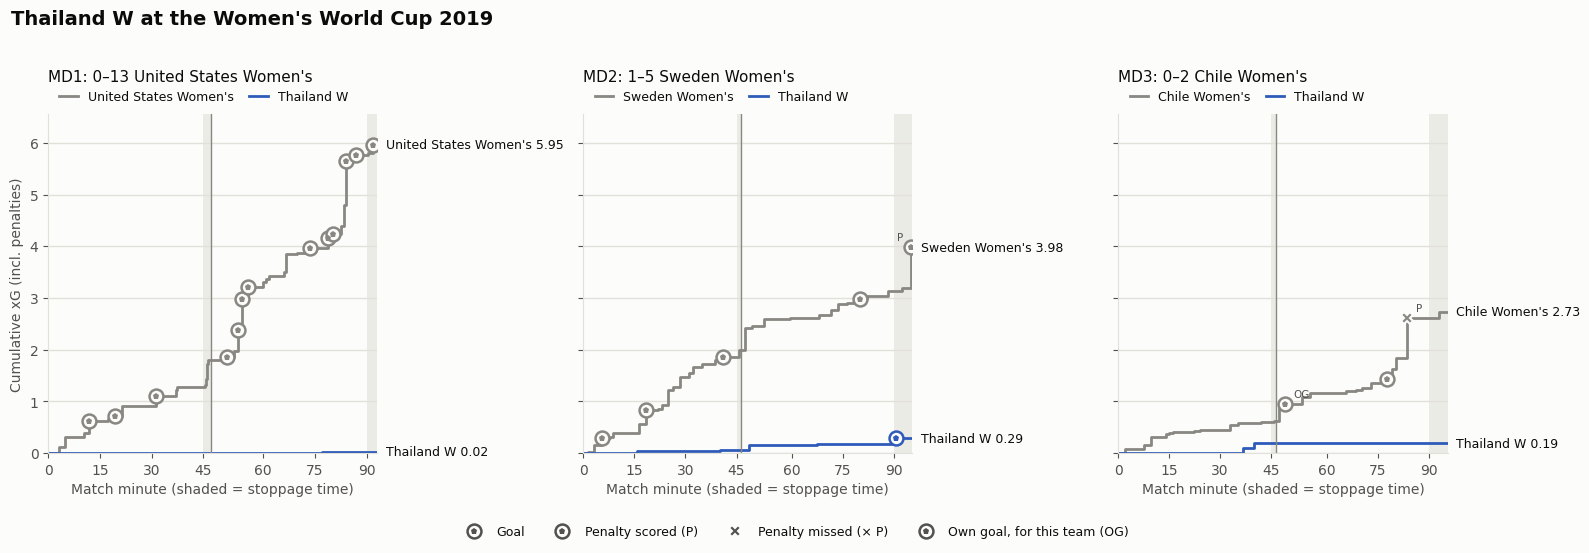

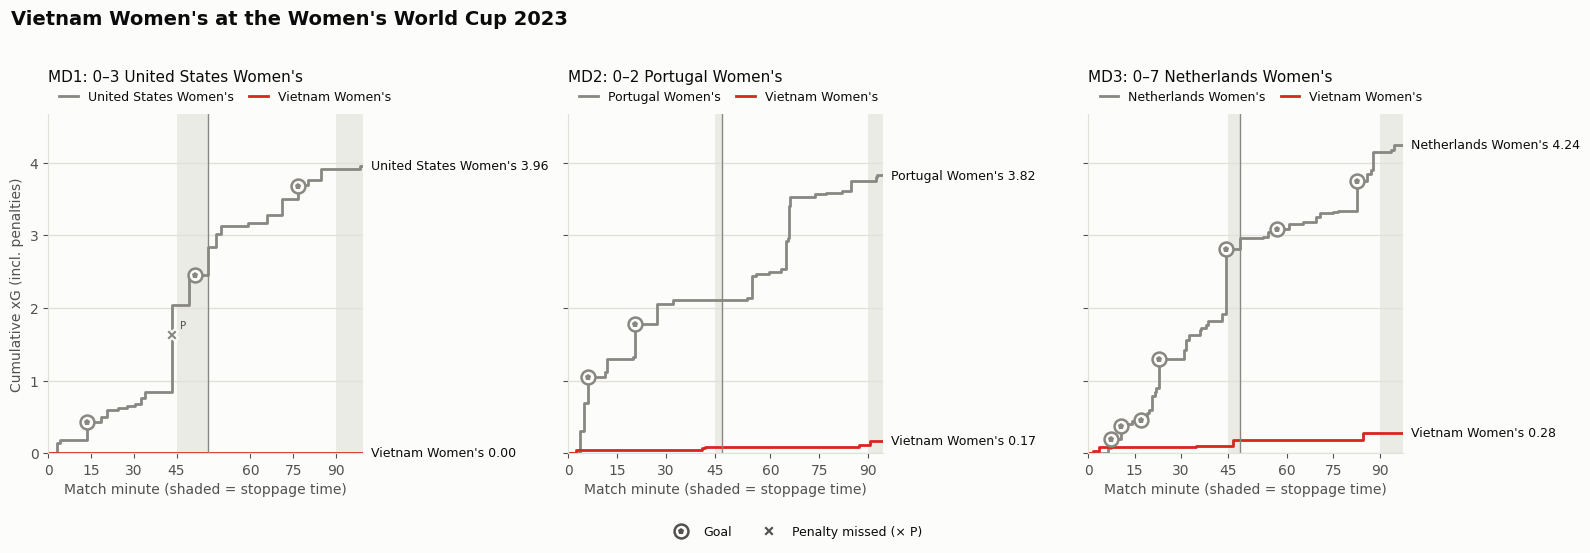

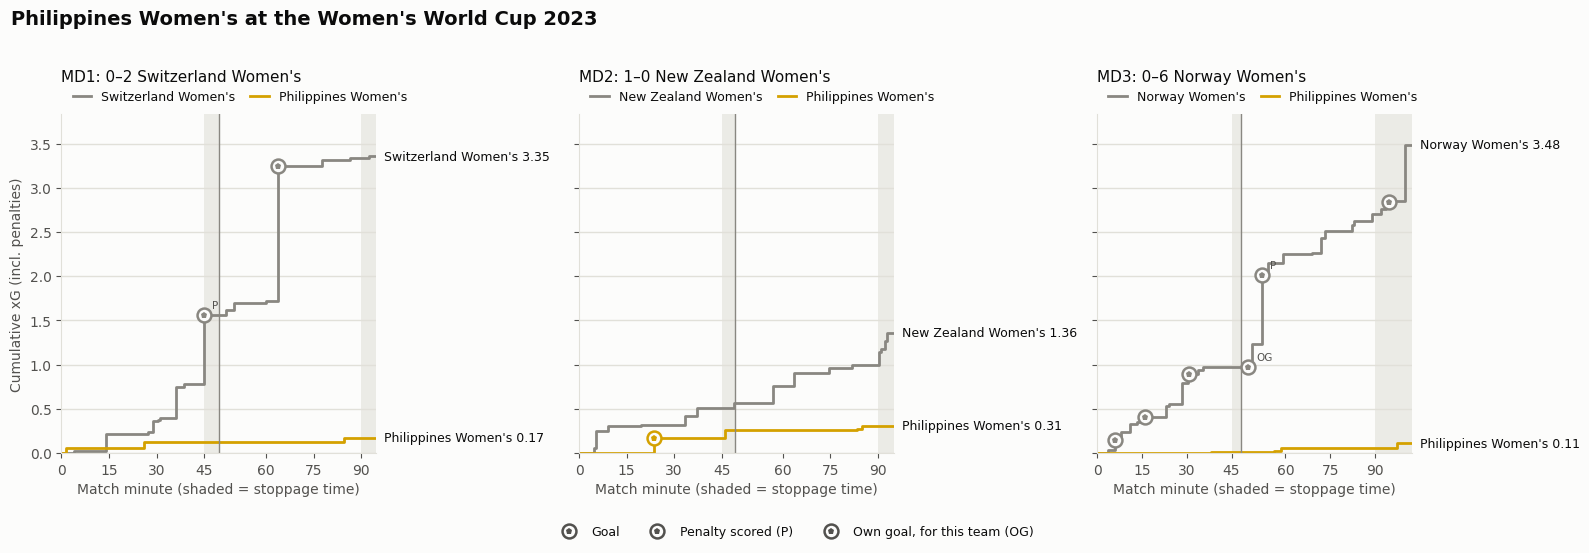

In [204]:
for sea_id in teams_sea:
    plot_team_timelines(sea_id, matches_sea[matches_sea["team_id"] == sea_id], timelines,
                        team_names, match_end, half_time)

### xG before and after a goal conceded

In [205]:
first_goal = first_goal_rates(timelines, matches_sea, match_end, team_names)

In [206]:
first_goal

,match_id,team,opponent,first_conceded_elapsed,opp_mins_before,opp_mins_after,opp_shots_before,opp_shots_after,opp_npxg_before,opp_npxg_after,opp_npxg_per15_before,opp_npxg_per15_after,opp_xg_before,opp_xg_after,opp_xg_per15_before,opp_xg_per15_after
0,22943,Thailand W,United States Women's,11.750000,11.750000,83.633333,5,34,0.626619,5.326846,0.799939,0.955393,0.626619,5.326846,0.799939,0.955393
1,22973,Thailand W,Sweden Women's,5.366667,5.366667,91.266667,3,32,0.293133,2.903736,0.819316,0.477239,0.293133,3.687236,0.819316,0.606010
2,68343,Thailand W,Chile Women's,49.166667,49.166667,47.983333,17,12,0.960012,0.990463,0.292885,0.309627,0.960012,1.773963,0.292885,0.554556
3,3893789,Philippines Women's,Switzerland Women's,44.900000,44.900000,54.200000,9,9,0.778172,1.792001,0.259968,0.495941,1.561672,1.792001,0.521717,0.495941
4,3893820,Philippines Women's,Norway Women's,5.933333,5.933333,99.350000,2,30,0.154512,2.543037,0.390619,0.383951,0.154512,3.326537,0.390619,0.502245
5,3893792,Vietnam Women's,United States Women's,13.633333,13.633333,96.566667,4,25,0.431361,2.741507,0.474602,0.425847,0.431361,3.525007,0.474602,0.547550
6,3893810,Vietnam Women's,Portugal Women's,6.150000,6.150000,90.350000,3,26,1.047119,2.776367,2.553950,0.460935,1.047119,2.776367,2.553950,0.460935
7,3893827,Vietnam Women's,Netherlands Women's,7.466667,7.466667,94.100000,2,39,0.194149,4.044203,0.390032,0.644666,0.194149,4.044203,0.390032,0.644666


## Shot map

In [207]:
shots = shot_table(events_matches_sea, teams_sea)

In [208]:
scores = {mid: score_from_timeline(tl) for mid, tl in timelines.items()}

In [209]:
profile_match = shot_profile(shots)

In [210]:
shots["team"] = shots["match_id"].map(dict(zip(matches_sea["match_id"], matches_sea["team_id"].map(team_names))))

In [211]:
profile_team = shot_profile(shots, by=("team", "side"))

In [212]:
own_goals = own_goal_counts(timelines)

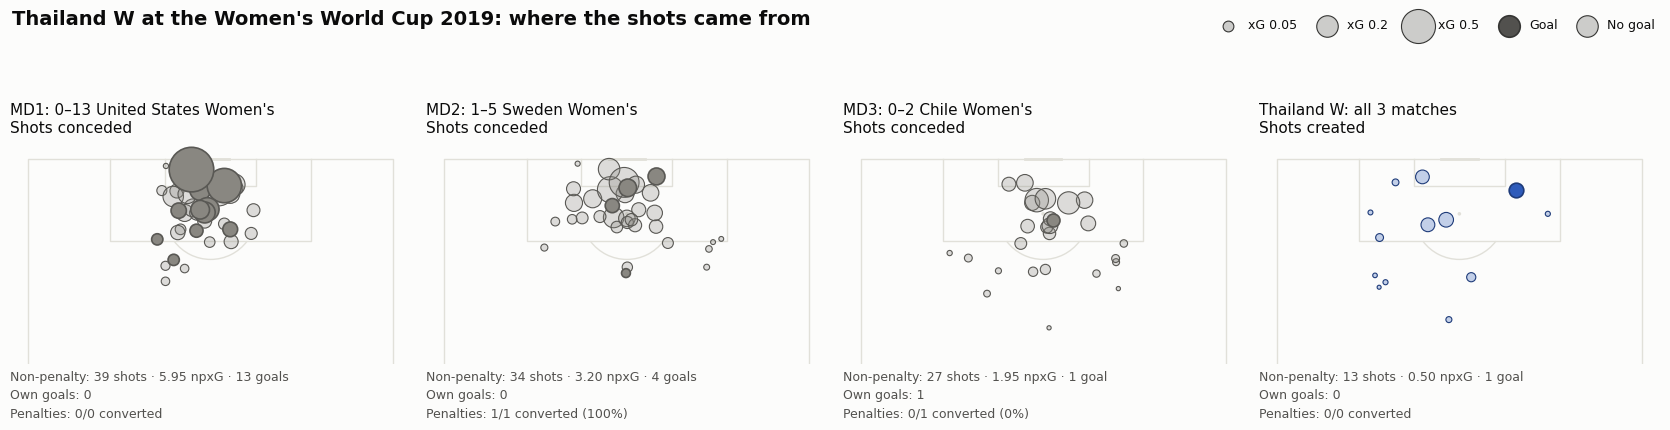

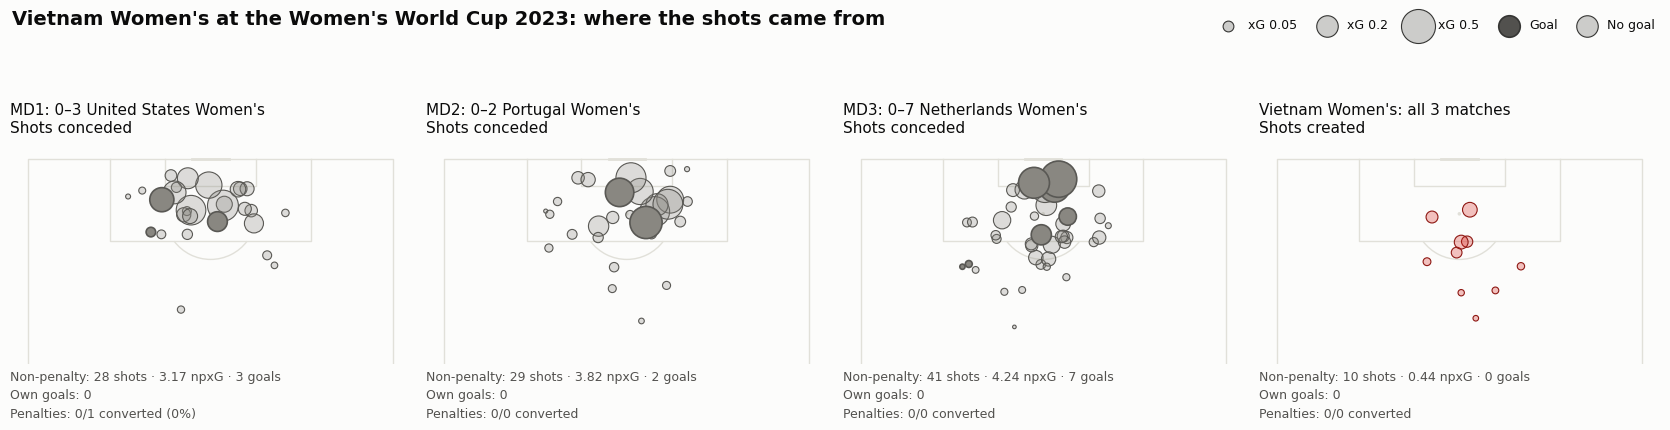

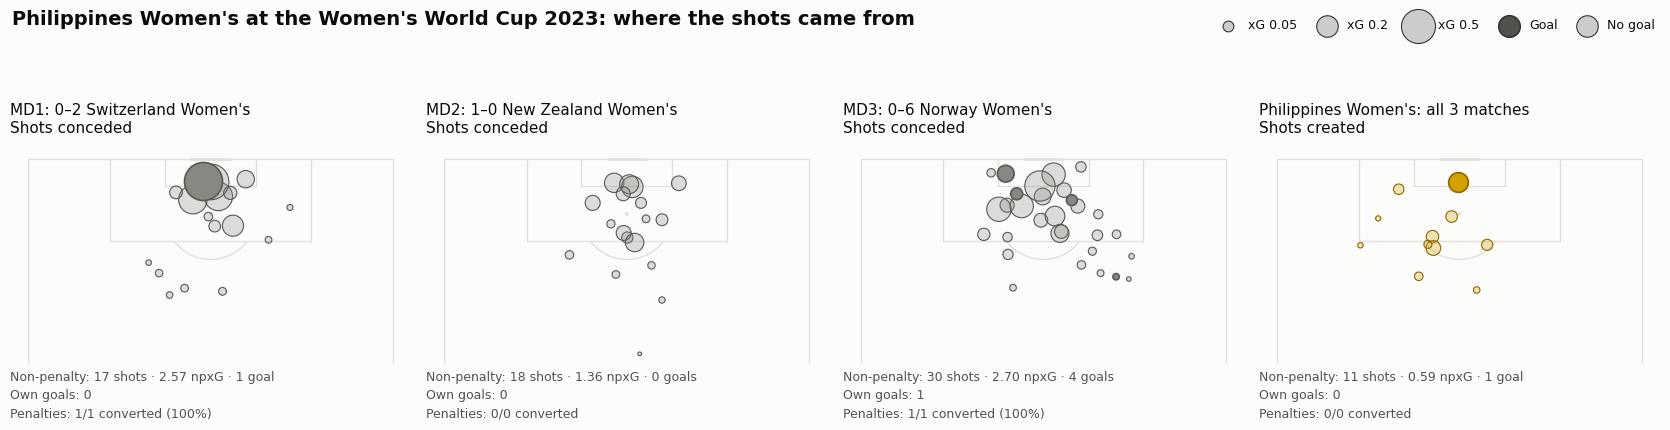

In [213]:
for sea_id in teams_sea:
    plot_team_shot_maps(sea_id, matches_sea[matches_sea["team_id"] == sea_id], shots, team_names, scores, own_goals)

## Shots by scenarios

In [214]:
shots = add_shot_origin(shots, events_matches_sea)

In [215]:
origins_match = origin_summary(shots).merge(
    labels[["match_id", "team", "opponent", "match_week"]], on="match_id", validate="m:1"
)

In [216]:
origin_table(origins_match)                      # npxG conceded by origin, per match

origin                                                 Counter  \
team                match_week opponent                          
Philippines Women's 1          Switzerland Women's    0.000000   
                    2          New Zealand Women's    0.000000   
                    3          Norway Women's         0.000000   
Thailand W          1          United States Women's  1.009639   
                    2          Sweden Women's         0.000000   
                    3          Chile Women's          0.000000   
Vietnam Women's     1          United States Women's  0.000000   
                    2          Portugal Women's       0.834851   
                    3          Netherlands Women's    0.000000   

origin                                                Direct set piece  \
team                match_week opponent                                  
Philippines Women's 1          Switzerland Women's            0.106836   
                    2          New Zealand Women's            0.681636   
                    3          Norway Women's                 0.378336   
Thailand W          1          United States Women's          1.075752   
                    2          Sweden Women's                 0.583975   
                    3          Chile Women's                  0.625254   
Vietnam Women's     1          United States Women's          0.807259   
                    2          Portugal Women's               0.140198   
                    3          Netherlands Women's            0.880484   

origin                                                Delayed set piece  \
team                match_week opponent                                   
Philippines Women's 1          Switzerland Women's             0.218114   
                    2          New Zealand Women's             0.000000   
                    3          Norway Women's                  0.000000   
Thailand W          1          United States Women's           0.485135   
                    2          Sweden Women's                  0.084553   
                    3          Chile Women's                   0.167344   
Vietnam Women's     1          United States Women's           0.218697   
                    2          Portugal Women's                0.045494   
                    3          Netherlands Women's             0.066359   

origin                                                Final-third throw-in  \
team                match_week opponent                                      
Philippines Women's 1          Switzerland Women's                0.130379   
                    2          New Zealand Women's                0.109277   
                    3          Norway Women's                     0.000000   
Thailand W          1          United States Women's              0.374981   
                    2          Sweden Women's                     1.351539   
                    3          Chile Women's                      0.167955   
Vietnam Women's     1          United States Women's              0.086542   
                    2          Portugal Women's                   0.719047   
                    3          Netherlands Women's                0.169557   

origin                                                Open play     total  
team                match_week opponent                                    
Philippines Women's 1          Switzerland Women's     2.114843  2.570172  
                    2          New Zealand Women's     0.569835  1.360747  
                    3          Norway Women's          2.319213  2.697549  
Thailand W          1          United States Women's   3.007958  5.953466  
                    2          Sweden Women's          1.176801  3.196869  
                    3          Chile Women's           0.989921  1.950474  
Vietnam Women's     1          United States Women's   2.060369  3.172868  
                    2          Portugal Women's        2.083896  3.823486  
             

In [217]:
origin_table(origins_match, value="shots")       # shots conceded

origin                                                Counter  \
team                match_week opponent                         
Philippines Women's 1          Switzerland Women's          0   
                    2          New Zealand Women's          0   
                    3          Norway Women's               0   
Thailand W          1          United States Women's        2   
                    2          Sweden Women's               0   
                    3          Chile Women's                0   
Vietnam Women's     1          United States Women's        0   
                    2          Portugal Women's             4   
                    3          Netherlands Women's          0   

origin                                                Direct set piece  \
team                match_week opponent                                  
Philippines Women's 1          Switzerland Women's                   2   
                    2          New Zealand Women's                   6   
                    3          Norway Women's                        5   
Thailand W          1          United States Women's                 7   
                    2          Sweden Women's                        5   
                    3          Chile Women's                         5   
Vietnam Women's     1          United States Women's                 8   
                    2          Portugal Women's                      4   
                    3          Netherlands Women's                   7   

origin                                                Delayed set piece  \
team                match_week opponent                                   
Philippines Women's 1          Switzerland Women's                    2   
                    2          New Zealand Women's                    0   
                    3          Norway Women's                         0   
Thailand W          1          United States Women's                  3   
                    2          Sweden Women's                         1   
                    3          Chile Women's                          2   
Vietnam Women's     1          United States Women's                  4   
                    2          Portugal Women's                       1   
                    3          Netherlands Women's                    1   

origin                                                Final-third throw-in  \
team                match_week opponent                                      
Philippines Women's 1          Switzerland Women's                       1   
                    2          New Zealand Women's                       3   
                    3          Norway Women's                            0   
Thailand W          1          United States Women's                     3   
                    2          Sweden Women's                           11   
                    3          Chile Women's                             3   
Vietnam Women's     1          United States Women's                     1   
                    2          Portugal Women's                          5   
                    3          Netherlands Women's                       4   

origin                                                Open play  total  
team                match_week opponent                                 
Philippines Women's 1          Switzerland Women's           12     17  
                    2          New Zealand Women's            9     18  
                    3          Norway Women's                25     30  
Thailand W          1          United States Women's         24     39  
                    2          Sweden Women's                17     34  
                    3          Chile Women's                 17     27  
Vietnam Women's     1          United States Women's         15     28  
                    2          Portugal Women's              15     29  
                    3          Netherlands Women's    

In [218]:
origin_table(origins_match, value="goals")       # goals conceded

origin                                                Counter  \
team                match_week opponent                         
Philippines Women's 1          Switzerland Women's          0   
                    2          New Zealand Women's          0   
                    3          Norway Women's               0   
Thailand W          1          United States Women's        2   
                    2          Sweden Women's               0   
                    3          Chile Women's                0   
Vietnam Women's     1          United States Women's        0   
                    2          Portugal Women's             0   
                    3          Netherlands Women's          0   

origin                                                Direct set piece  \
team                match_week opponent                                  
Philippines Women's 1          Switzerland Women's                   0   
                    2          New Zealand Women's                   0   
                    3          Norway Women's                        0   
Thailand W          1          United States Women's                 2   
                    2          Sweden Women's                        1   
                    3          Chile Women's                         0   
Vietnam Women's     1          United States Women's                 0   
                    2          Portugal Women's                      0   
                    3          Netherlands Women's                   1   

origin                                                Delayed set piece  \
team                match_week opponent                                   
Philippines Women's 1          Switzerland Women's                    0   
                    2          New Zealand Women's                    0   
                    3          Norway Women's                         0   
Thailand W          1          United States Women's                  0   
                    2          Sweden Women's                         0   
                    3          Chile Women's                          0   
Vietnam Women's     1          United States Women's                  1   
                    2          Portugal Women's                       0   
                    3          Netherlands Women's                    0   

origin                                                Final-third throw-in  \
team                match_week opponent                                      
Philippines Women's 1          Switzerland Women's                       0   
                    2          New Zealand Women's                       0   
                    3          Norway Women's                            0   
Thailand W          1          United States Women's                     0   
                    2          Sweden Women's                            2   
                    3          Chile Women's                             0   
Vietnam Women's     1          United States Women's                     0   
                    2          Portugal Women's                          0   
                    3          Netherlands Women's                       0   

origin                                                Open play  total  
team                match_week opponent                                 
Philippines Women's 1          Switzerland Women's            1      1  
                    2          New Zealand Women's            0      0  
                    3          Norway Women's                 4      4  
Thailand W          1          United States Women's          9     13  
                    2          Sweden Women's                 1      4  
                    3          Chile Women's                  1      1  
Vietnam Women's     1          United States Women's          2      3  
                    2          Portugal Women's               2      2  
                    3          Netherlands Women's    

In [219]:
origin_table(origins_match, side="sea")          # npxG created

origin                                                Transition   Counter  \
team                match_week opponent                                      
Philippines Women's 1          Switzerland Women's      0.000000  0.000000   
                    2          New Zealand Women's      0.012747  0.000000   
                    3          Norway Women's           0.000000  0.000000   
Thailand W          1          United States Women's    0.000000  0.000000   
                    2          Sweden Women's           0.000000  0.118996   
                    3          Chile Women's            0.000000  0.082523   
Vietnam Women's     2          Portugal Women's         0.000000  0.000000   
                    3          Netherlands Women's      0.000000  0.061200   

origin                                                Direct set piece  \
team                match_week opponent                                  
Philippines Women's 1          Switzerland Women's            0.125763   
                    2          New Zealand Women's            0.167763   
                    3          Norway Women's                 0.065148   
Thailand W          1          United States Women's          0.000000   
                    2          Sweden Women's                 0.000000   
                    3          Chile Women's                  0.081431   
Vietnam Women's     2          Portugal Women's               0.087050   
                    3          Netherlands Women's            0.119477   

origin                                                Delayed set piece  \
team                match_week opponent                                   
Philippines Women's 1          Switzerland Women's             0.000000   
                    2          New Zealand Women's             0.000000   
                    3          Norway Women's                  0.000000   
Thailand W          1          United States Women's           0.000000   
                    2          Sweden Women's                  0.000000   
                    3          Chile Women's                   0.010486   
Vietnam Women's     2          Portugal Women's                0.000000   
                    3          Netherlands Women's             0.000000   

origin                                                Final-third throw-in  \
team                match_week opponent                                      
Philippines Women's 1          Switzerland Women's                0.000000   
                    2          New Zealand Women's                0.000000   
                    3          Norway Women's                     0.018391   
Thailand W          1          United States Women's              0.011200   
                    2          Sweden Women's                     0.000000   
                    3          Chile Women's                      0.000000   
Vietnam Women's     2          Portugal Women's                   0.000000   
                    3          Netherlands Women's                0.095757   

origin                                                Open play     total  
team                match_week opponent                                    
Philippines Women's 1          Switzerland Women's     0.047550  0.173312  
                    2          New Zealand Women's     0.125089  0.305599  
                    3          Norway Women's          0.027857  0.111396  
Thailand W          1          United States Women's   0.009110  0.020310  
                    2          Sweden Women's          0.167481  0.286477  
                    3          Chile Women's           0.015560  0.190001  
Vietnam Women's     2          Portugal Women's        0.078453  0.165503  
                    3          Netherlands Women's     0.000000  0.276434

In [220]:
shots["team"] = shots["match_id"].map(dict(zip(matches_sea["match_id"], matches_sea["team_id"].map(team_names))))

In [221]:
origins_team = origin_summary(shots, by=("team", "side"))    # per team, over its three matches

In [222]:
conceded = origins_team[origins_team["side"] == "opp"]

In [223]:
created = origins_team[origins_team["side"] == "sea"]

In [224]:
conceded

,team,side,origin,shots,goals,npxg,npxg_per_shot,npxg_share
0,Philippines Women's,opp,Delayed set piece,2,0,0.218114,0.109057,0.032906
1,Philippines Women's,opp,Direct set piece,13,0,1.166807,0.089754,0.176030
2,Philippines Women's,opp,Final-third throw-in,4,0,0.239656,0.059914,0.036156
3,Philippines Women's,opp,Open play,46,5,5.003891,0.108780,0.754909
8,Thailand W,opp,Counter,2,2,1.009639,0.504820,0.090952
9,Thailand W,opp,Delayed set piece,6,0,0.737033,0.122839,0.066395
10,Thailand W,opp,Direct set piece,17,3,2.284982,0.134411,0.205839
11,Thailand W,opp,Final-third throw-in,17,2,1.894475,0.111440,0.170661
12,Thailand W,opp,Open play,58,11,5.174679,0.089219,0.466153
18,Vietnam Women's,opp,Counter,4,0,0.834851,0.208713,0.074310


In [225]:
created

,team,side,origin,shots,goals,npxg,npxg_per_shot,npxg_share
4,Philippines Women's,sea,Direct set piece,5,1,0.358674,0.071735,0.607605
5,Philippines Women's,sea,Final-third throw-in,1,0,0.018391,0.018391,0.031155
6,Philippines Women's,sea,Open play,4,0,0.200496,0.050124,0.339646
7,Philippines Women's,sea,Transition,1,0,0.012747,0.012747,0.021593
13,Thailand W,sea,Counter,3,1,0.201520,0.067173,0.405646
14,Thailand W,sea,Delayed set piece,1,0,0.010486,0.010486,0.021108
15,Thailand W,sea,Direct set piece,1,0,0.081431,0.081431,0.163915
16,Thailand W,sea,Final-third throw-in,1,0,0.011200,0.011200,0.022545
17,Thailand W,sea,Open play,7,0,0.192150,0.027450,0.386786
23,Vietnam Women's,sea,Counter,1,0,0.061200,0.061200,0.138481


## Losing the ball

In [226]:
possessions = possession_table(events_matches_sea)

In [227]:
losses = ball_losses(events_matches_sea, teams_sea)

In [228]:
print(len(losses), losses["ended_in_shot"].sum(), losses["transition_loss"].sum())

588 24 0


In [229]:
losses["cause"].value_counts()

cause
Misplaced pass (open play)    298
Miscontrol                     72
Misplaced pass (restart)       66
Dispossessed                   38
Aerial duel lost               30
Other                          28
Shot                           24
Foul committed                 12
Failed dribble                 12
Clearance                       8
Name: count, dtype: int64

In [230]:
losses = add_next_possession_shots(losses, shots)

In [231]:
l = losses[~losses["ended_in_shot"]]

In [232]:
oh = l[l["own_half"]]

In [233]:
print(len(l), len(oh), oh["led_to_shot"].sum(), oh["quick_shot"].sum(),
      round(oh["opp_npxg"].sum(), 2), oh["opp_goals"].sum())

564 351 82 24 11.77 15


In [234]:
labels = matches_sea[["match_id", "match_week", "team_id"]].assign(team=lambda d: d["team_id"].map(team_names))

In [235]:
losses = losses.merge(labels[["match_id", "match_week", "team"]], on="match_id", how="left")

In [236]:
loss_by_match = loss_summary(losses, by=("team", "match_week"))

In [237]:
loss_by_team = loss_summary(losses, by=("team",))

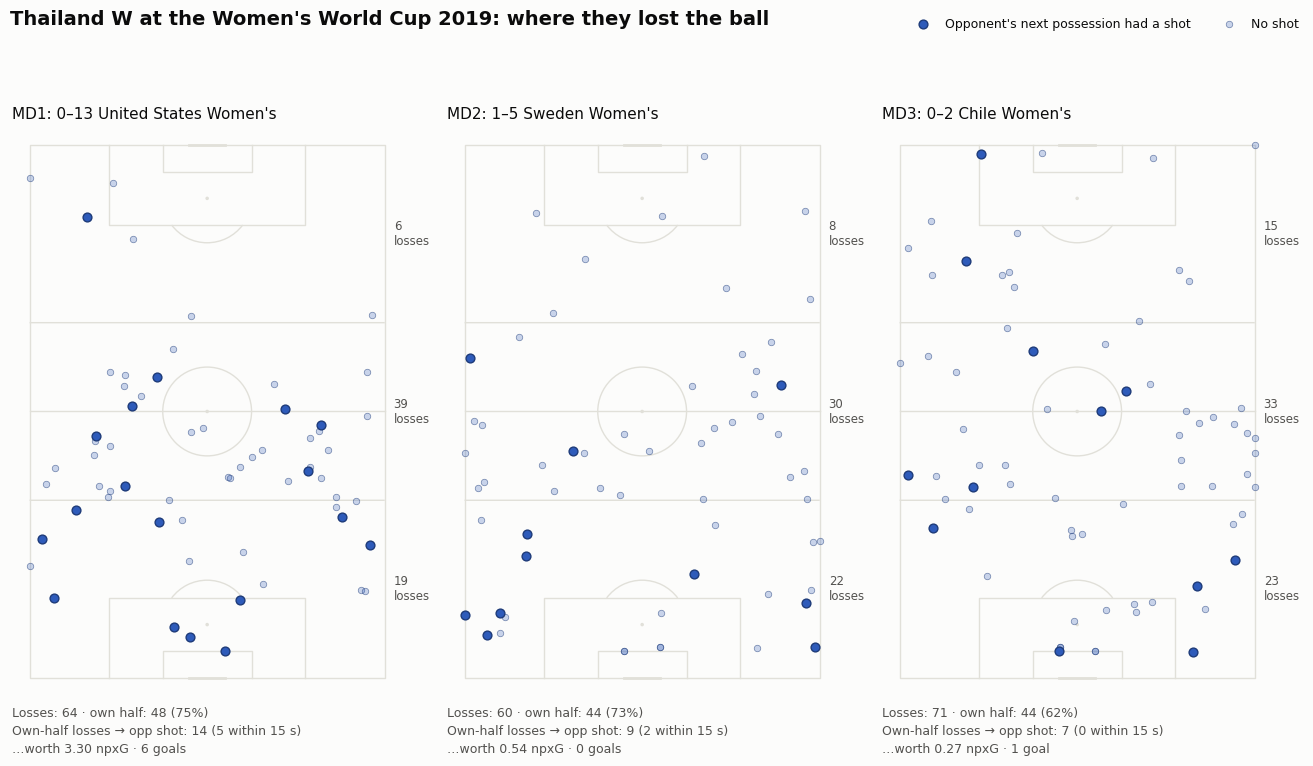

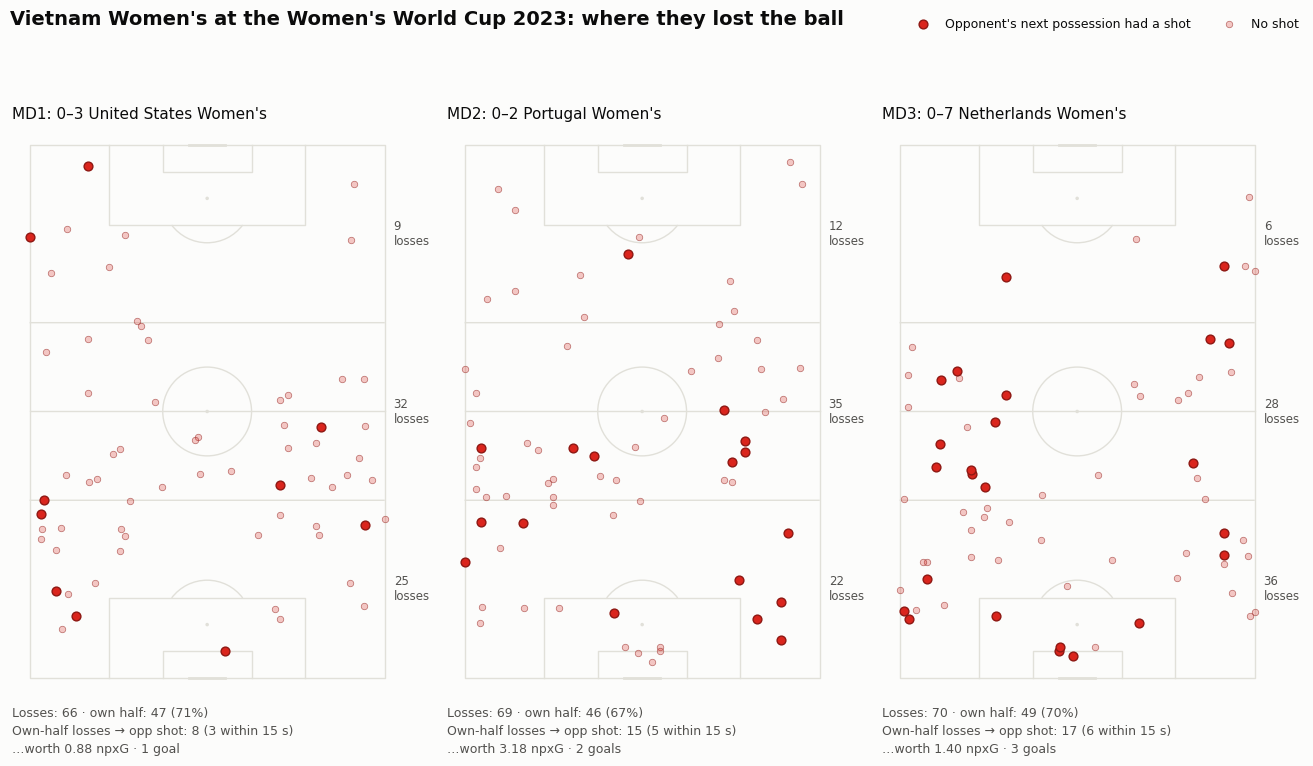

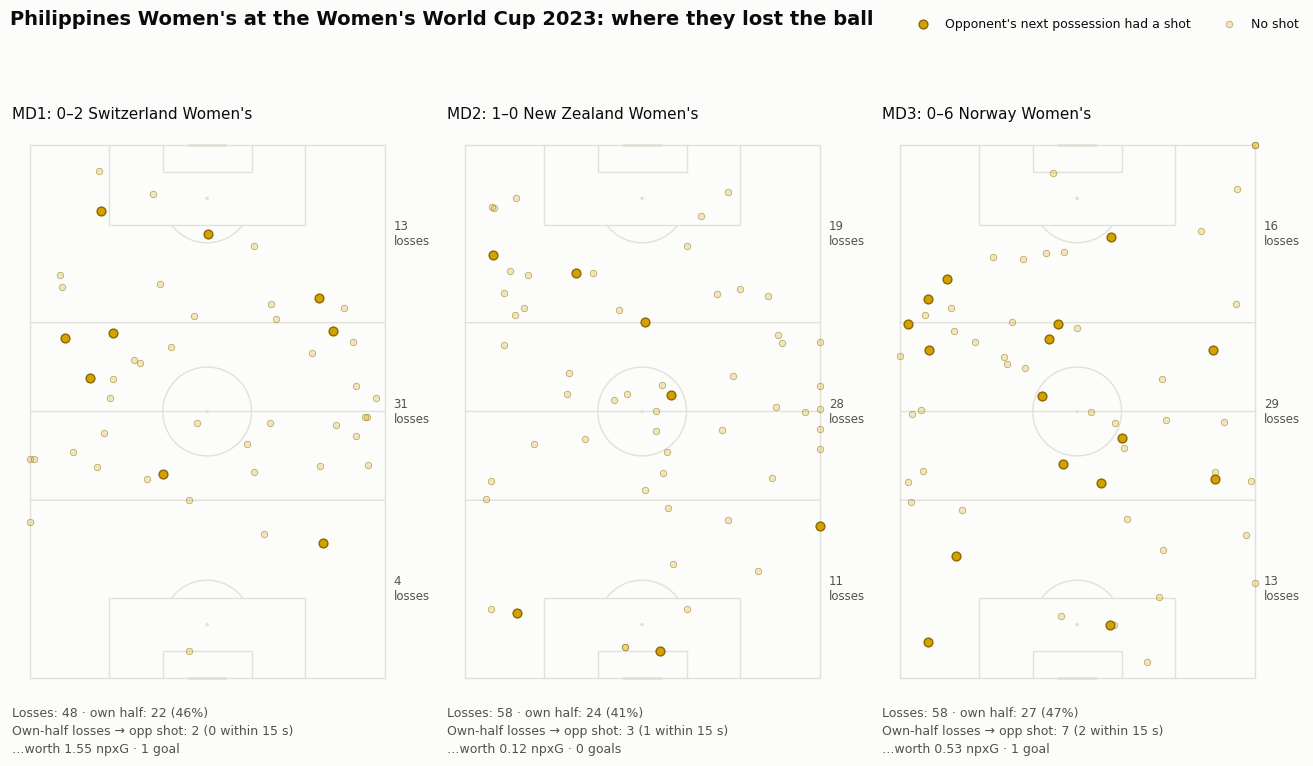

In [238]:
for sea_id in teams_sea:
    plot_team_loss_maps(sea_id, matches_sea[matches_sea["team_id"] == sea_id], losses, team_names, scores)

In [239]:
open_losses = losses[~losses["ended_in_shot"]]

In [240]:
own_box = open_losses[(open_losses["location_x"] <= 18) & open_losses["location_y"].between(18, 62)]

In [241]:
print(len(own_box), own_box["led_to_shot"].sum(), round(own_box["opp_npxg"].sum(), 2), own_box["opp_goals"].sum())

46 14 1.85 1


In [242]:
own_box.groupby("team").agg(losses=("possession", "size"), led_to_shot=("led_to_shot", "sum"),
                                  opp_npxg=("opp_npxg", "sum"), opp_goals=("opp_goals", "sum"))

,losses,led_to_shot,opp_npxg,opp_goals
team,,,,
Philippines Women's,9,2,0.128212,0
Thailand W,19,5,0.888739,0
Vietnam Women's,18,7,0.837896,1


In [243]:
own_box["cause"].value_counts()

cause
Misplaced pass (restart)      26
Misplaced pass (open play)    19
Other                          1
Name: count, dtype: int64

In [244]:
own_box.loc[own_box["cause"] == "Misplaced pass (restart)", "pass_type"].value_counts()

pass_type
Goal Kick    23
Free Kick     3
Name: count, dtype: int64

In [245]:
losses = add_won_location(losses, events_matches_sea)

In [246]:
loss_by_match_won = loss_summary(losses.assign(zone=losses["won_zone"], own_half=losses["won_own_half"]),
                                 by=("team", "match_week"))

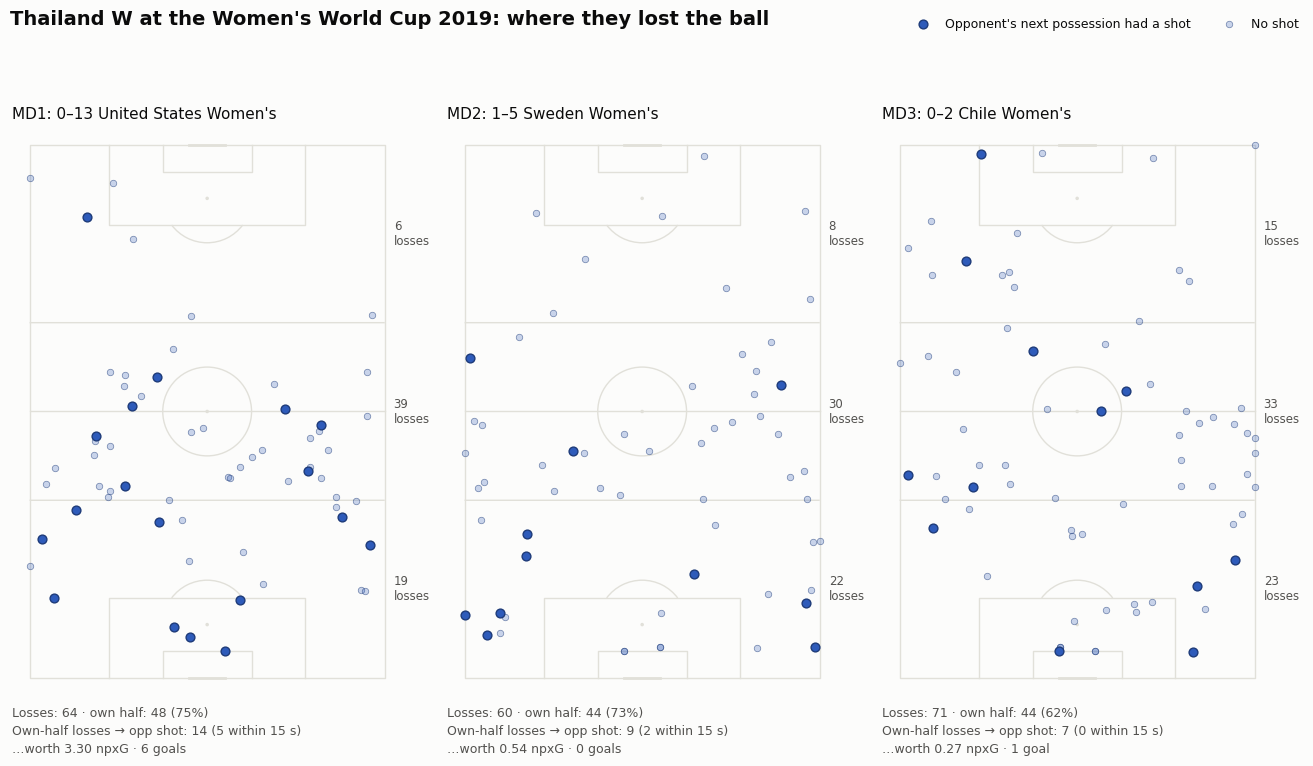

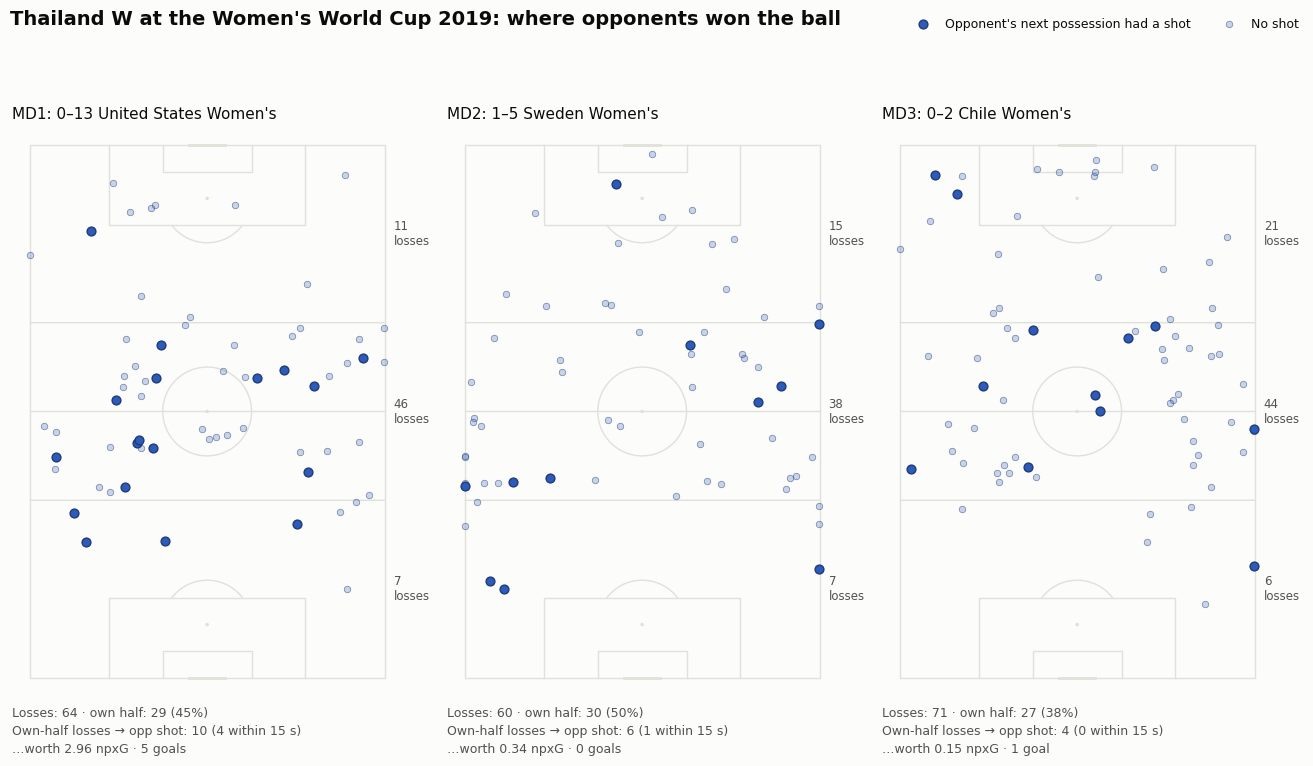

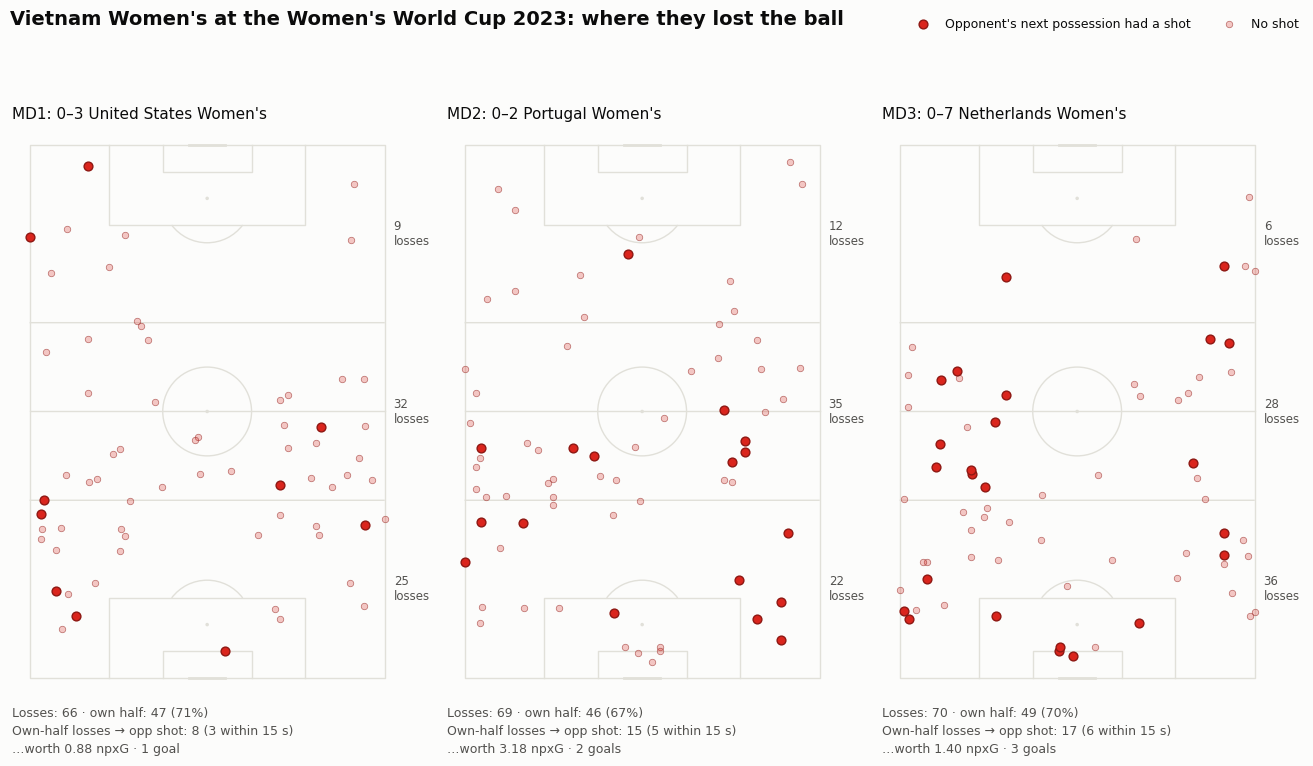

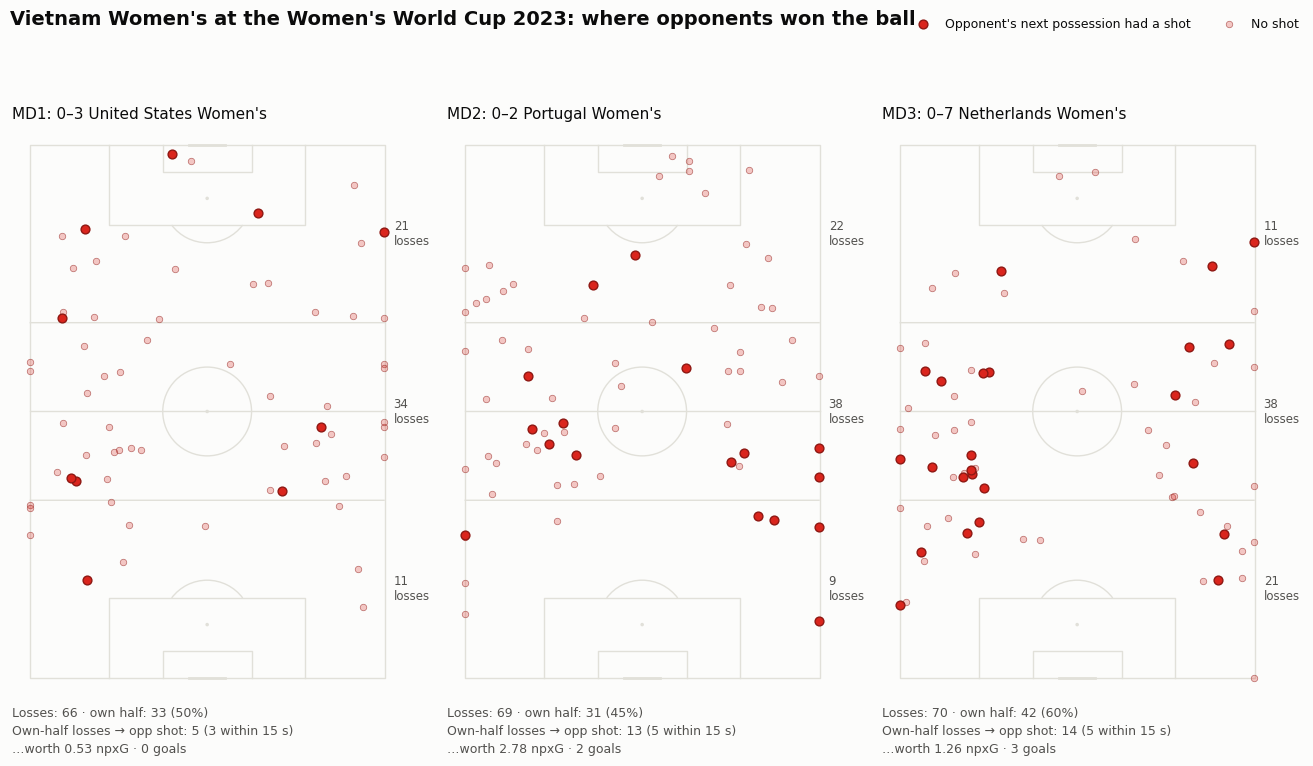

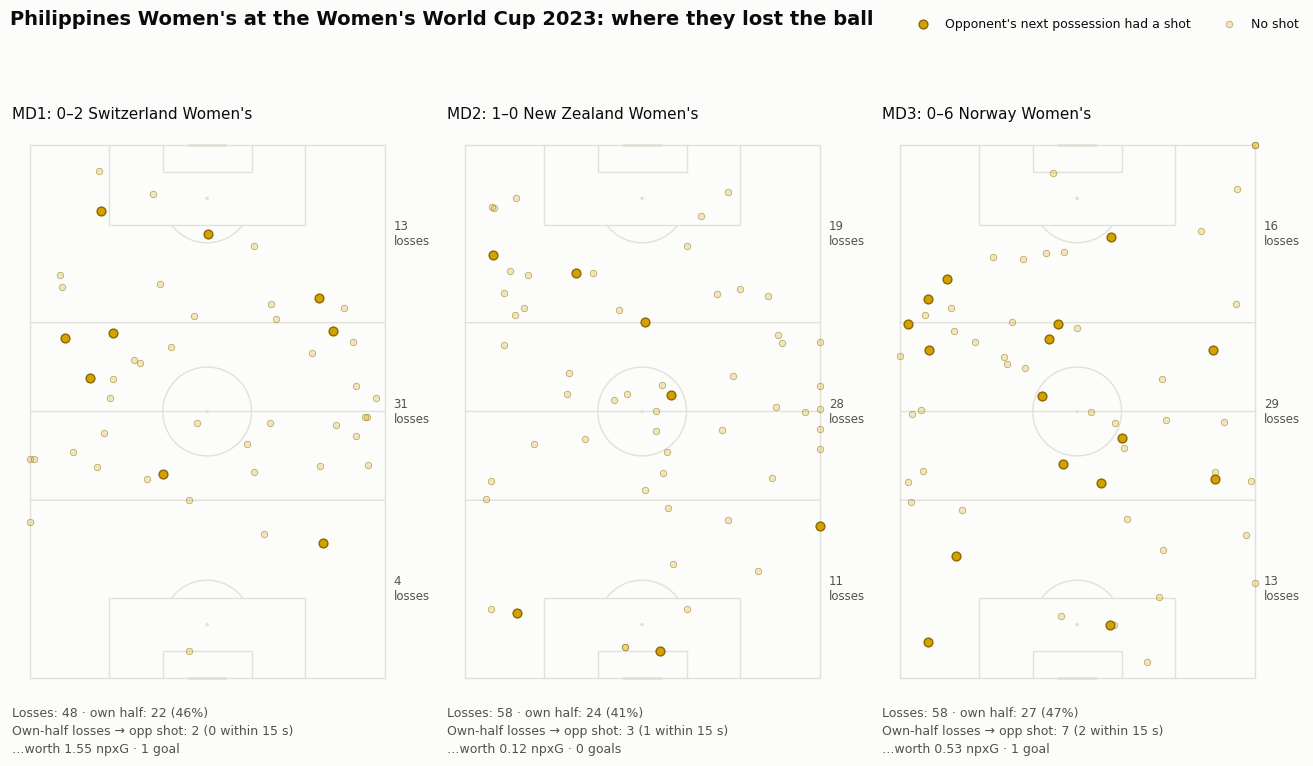

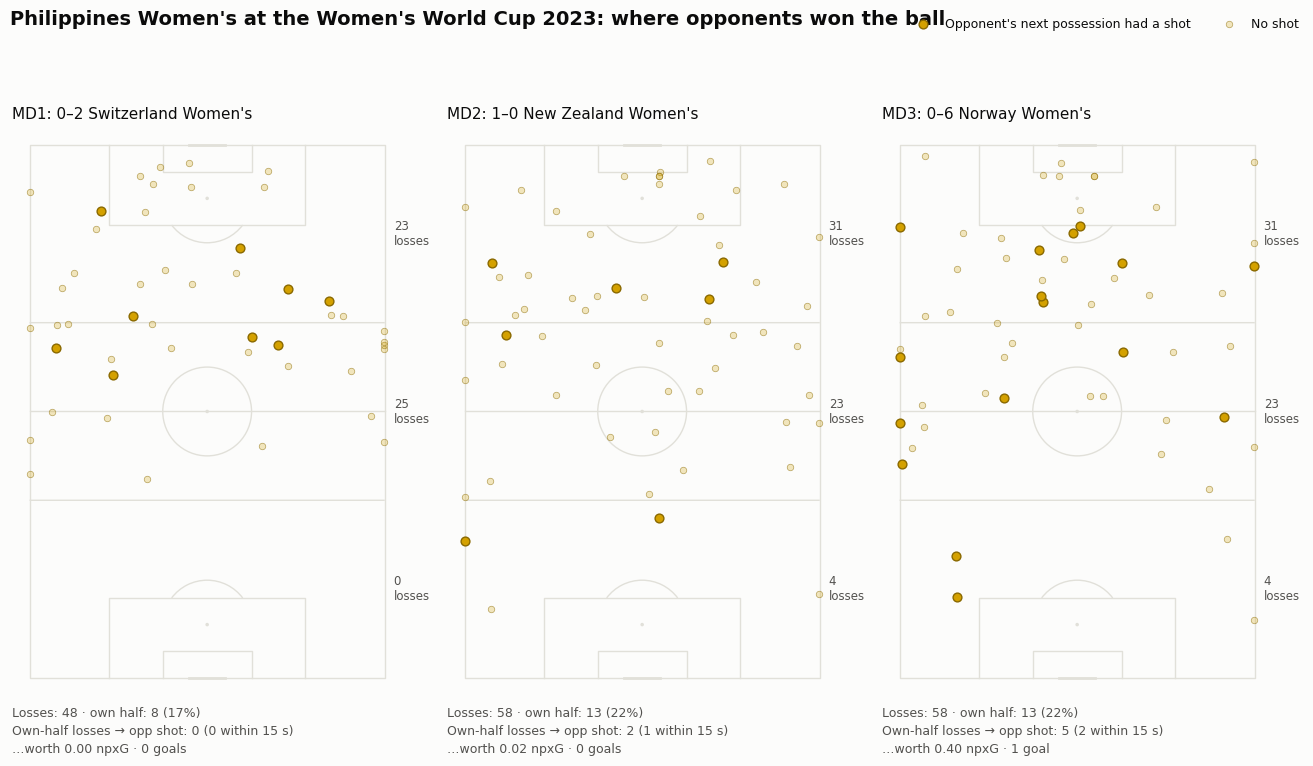

In [247]:
for sea_id in teams_sea:
    team_rows = matches_sea[matches_sea["team_id"] == sea_id]
    plot_team_loss_maps(sea_id, team_rows, losses, team_names, scores)                    # where it was played from
    plot_team_loss_maps(sea_id, team_rows, losses, team_names, scores, location="won")    # where the opponent won it

## Winning the ball

In [248]:
regains = ball_regains(events_matches_sea, teams_sea)

In [249]:
print(len(regains), regains["how"].value_counts().to_dict())

587 {'Restart': 315, 'Active': 227, 'Keeper': 45}


In [250]:
regains.loc[regains["how"] == "Active", "type"].value_counts().to_dict()

{'Ball Recovery': 94,
 'Pass': 75,
 'Duel': 34,
 'Interception': 12,
 'Goal Keeper': 10,
 'Block': 1,
 'Clearance': 1}

In [251]:
regains = add_regain_outcome(regains, events_matches_sea, shots)

In [252]:
print(regains["kept_secs"].isna().sum(), (regains["kept_secs"] < 0).sum())

0 0


In [253]:
regains = regains.merge(labels[["match_id", "match_week", "team"]], on="match_id", how="left")

In [254]:
regain_by_match = regain_summary(regains, by=("team", "match_week"))

In [255]:
regain_by_team = regain_summary(regains, by=("team",))

In [256]:
all_teams = events_matches_sea["team_id"].dropna().unique()

In [257]:
defending = defending_profile(events_matches_sea, all_teams, by=("match_id", "team_id"))

In [258]:
defending

,match_id,team_id,engagements,defensive_distance,pressures,pressure_height,pressures_opp_half,counterpressures,clearances_blocks,clearances_blocks_own_third,pressures_opp_half_pct
0,22943,1107,75,24.057333,180,31.094444,19,37,83,80,0.105556
1,22943,1214,27,64.025926,67,70.904478,47,22,20,2,0.701493
2,22973,858,35,75.260000,128,79.810156,99,45,23,6,0.773438
3,22973,1107,70,23.751429,144,30.645139,14,23,51,50,0.097222
4,68343,1107,47,43.634043,136,45.161029,39,30,60,59,0.286765
5,68343,1209,31,54.416129,92,75.031522,71,29,38,13,0.771739
6,3893789,860,32,53.746875,106,60.789623,55,25,35,15,0.518868
7,3893789,1106,36,40.152778,314,53.254459,132,53,53,35,0.420382
8,3893792,1214,26,65.061538,87,73.328736,65,16,42,6,0.747126
9,3893792,16769,57,36.894737,188,38.585106,41,40,72,66,0.218085


In [259]:
block = dict(zip(defending["match_id"], defending["defensive_distance"]))

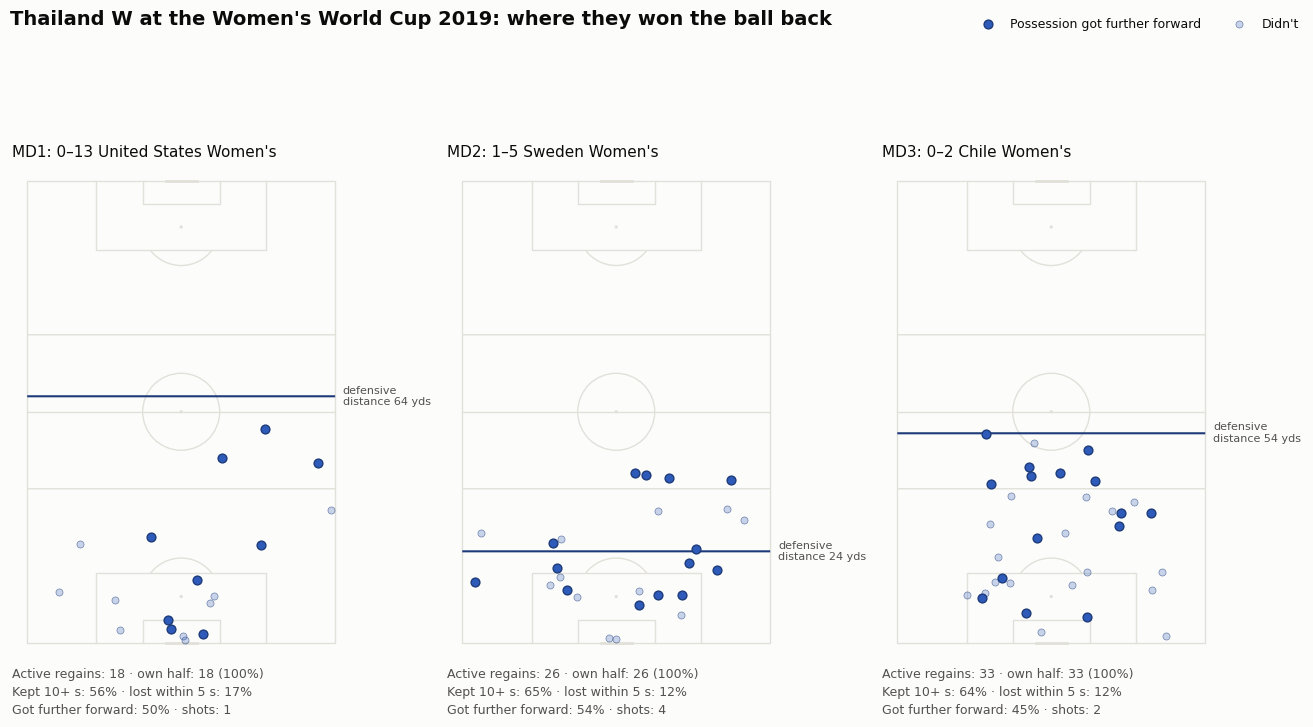

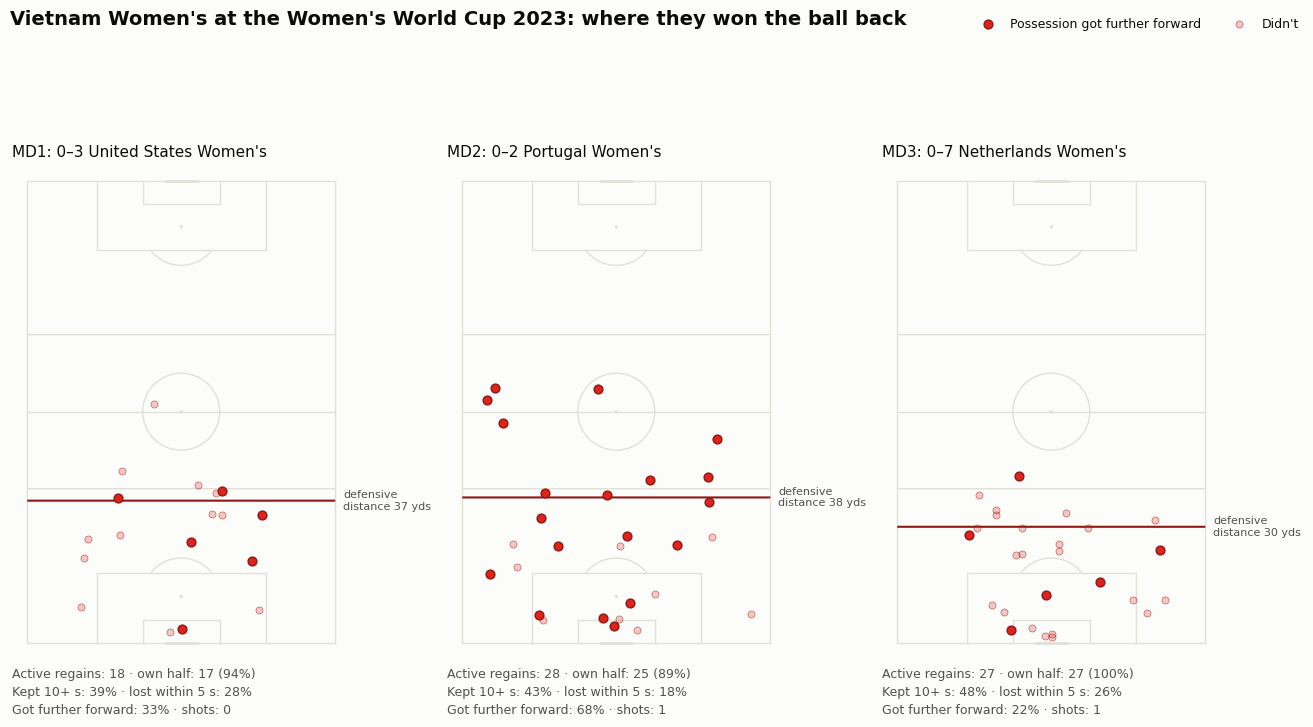

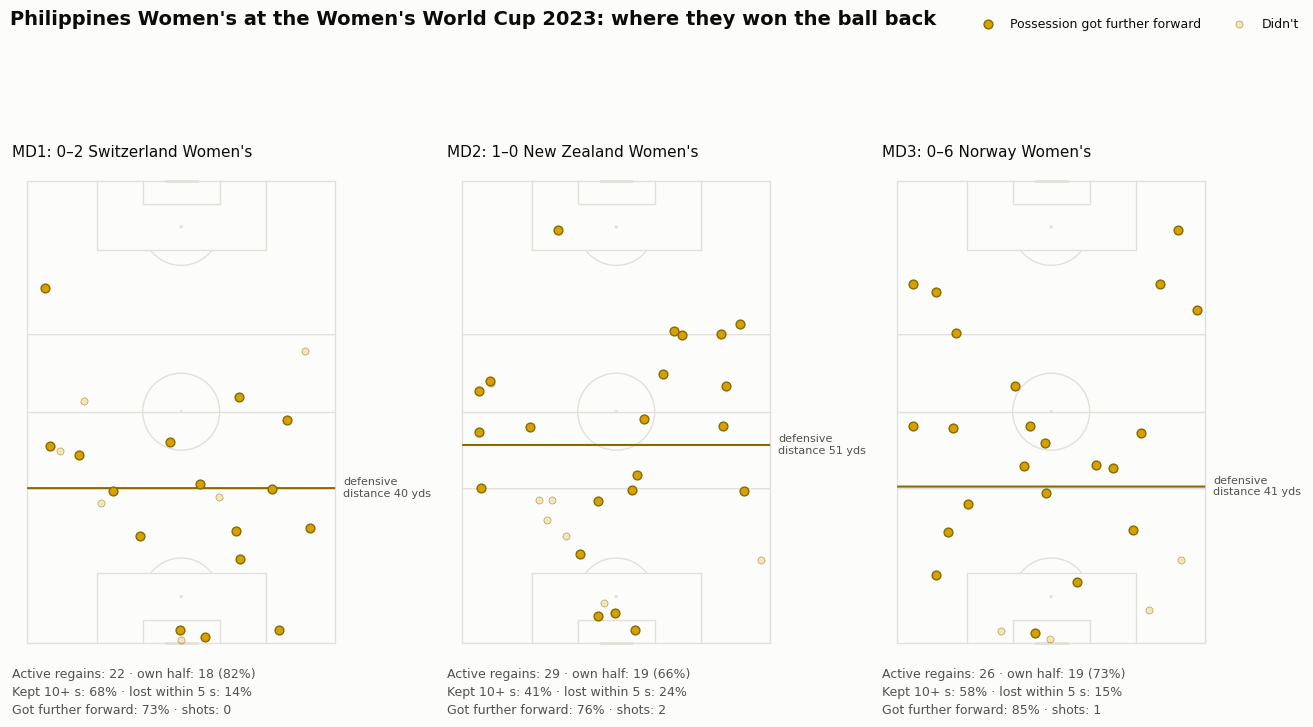

In [260]:
for sea_id in teams_sea:
    plot_team_regain_maps(sea_id, matches_sea[matches_sea["team_id"] == sea_id], regains,
                          team_names, scores, block=block)

## PPDA

In [261]:
opp_passes_in_zone = (
    events_matches_sea_passes[events_matches_sea_passes["pass_complete"] & (events_matches_sea_passes["location_x"] <= 72)]
    .groupby(match_keys)
    .size()
    .reset_index(name="opp_passes_in_zone")
)
opp_passes_in_zone["side"] = opp_passes_in_zone["side"].map({"sea": "opp", "opp": "sea"})   # these passes count against the other side

In [262]:
def_actions = pd.concat([
    events_matches_sea_passes_interception[match_keys + ["location_x"]],
    events_matches_sea_tackles[match_keys + ["location_x"]],
    events_matches_sea_interceptions[match_keys + ["location_x"]],
    events_matches_sea_blocks[match_keys + ["location_x"]],
    events_matches_sea_foul_committeds[match_keys + ["location_x"]],
    events_matches_sea_dribbled_pasts[match_keys + ["location_x"]],
], ignore_index=True)

In [263]:
def_actions_in_zone = (
    def_actions[def_actions["location_x"] >= 48]
    .groupby(match_keys)
    .size()
    .reset_index(name="def_actions_in_zone")
)

In [264]:
ppda_table = def_actions_in_zone.merge(opp_passes_in_zone, on=match_keys, how="left")

In [265]:
ppda_table["ppda"] = ppda_table["opp_passes_in_zone"] / ppda_table["def_actions_in_zone"]

In [266]:
ppda_table

,match_id,sea_team_id,match_week,side,def_actions_in_zone,opp_passes_in_zone,ppda
0,22943,1107,1,opp,38,128,3.368421
1,22943,1107,1,sea,9,298,33.111111
2,22973,1107,2,opp,56,157,2.803571
3,22973,1107,2,sea,7,262,37.428571
4,68343,1107,3,opp,41,165,4.024390
5,68343,1107,3,sea,21,273,13.000000
6,3893789,1106,1,opp,36,161,4.472222
7,3893789,1106,1,sea,33,470,14.242424
8,3893792,16769,1,opp,59,133,2.254237
9,3893792,16769,1,sea,24,229,9.541667


## Build up and Attack

### Passing stats aggregation

In [267]:
pass_style_match = events_matches_sea_passes_open_play.groupby(match_keys).agg(
    passes=("pass_complete", "size"), 
    passes_completed=("pass_complete", "sum"),
    passes_long=("pass_long", "sum"), 
    passes_long_completed=("pass_complete", lambda x: (
        x & events_matches_sea_passes_open_play.loc[x.index, "pass_long"]).sum()),
    passes_short_completed=("pass_complete", lambda x: (
        x & ~events_matches_sea_passes_open_play.loc[x.index, "pass_long"]).sum()),
    passes_forward=("pass_forward", "sum"), 
    forward_completed=("pass_complete", lambda x: (
        x & events_matches_sea_passes_open_play.loc[x.index, "pass_forward"]).sum()),
    passes_backward=("pass_backward", "sum"),
    passes_under_pressure=("under_pressure", "sum"), 
    passes_under_pressure_completed=("pass_complete", lambda x: (
        x & events_matches_sea_passes_open_play.loc[x.index, "under_pressure"]).sum()),
    pass_length_avg=("pass_length", "mean"),
).reset_index()

In [268]:
pass_style_team = events_matches_sea_passes_open_play.groupby(team_keys).agg(
    passes=("pass_complete", "size"), 
    passes_completed=("pass_complete", "sum"),
    passes_long=("pass_long", "sum"), 
    passes_long_completed=("pass_complete", lambda x: (
        x & events_matches_sea_passes_open_play.loc[x.index, "pass_long"]).sum()),
    passes_short_completed=("pass_complete", lambda x: (
        x & ~events_matches_sea_passes_open_play.loc[x.index, "pass_long"]).sum()),
    passes_forward=("pass_forward", "sum"), 
    forward_completed=("pass_complete", lambda x: (
        x & events_matches_sea_passes_open_play.loc[x.index, "pass_forward"]).sum()),
    passes_backward=("pass_backward", "sum"),
    passes_under_pressure=("under_pressure", "sum"), 
    passes_under_pressure_completed=("pass_complete", lambda x: (
        x & events_matches_sea_passes_open_play.loc[x.index, "under_pressure"]).sum()),
    pass_length_avg=("pass_length", "mean"),
).reset_index()

In [269]:
for p in (pass_style_match, pass_style_team):
    p["pass_completion_pct"] = p["passes_completed"] / p["passes"]
    p["pass_long_pct"] = p["passes_long"] / p["passes"]
    p["pass_long_completion_pct"] = p["passes_long_completed"] / p["passes_long"]
    p["pass_short_completion_pct"] = p["passes_short_completed"] / (p["passes"] - p["passes_long"])
    p["pass_forward_pct"] = p["passes_forward"] / p["passes"]
    p["pass_backward_pct"] = p["passes_backward"] / p["passes"]
    p["pass_forward_completion_pct"] = p["forward_completed"] / p["passes_forward"]
    p["pass_under_pressure_completion_pct"] = p["passes_under_pressure_completed"] / p["passes_under_pressure"]

In [270]:
pass_style_match

,match_id,sea_team_id,match_week,side,passes,passes_completed,passes_long,passes_long_completed,passes_short_completed,passes_forward,...,passes_under_pressure_completed,pass_length_avg,pass_completion_pct,pass_long_pct,pass_long_completion_pct,pass_short_completion_pct,pass_forward_pct,pass_backward_pct,pass_forward_completion_pct,pass_under_pressure_completion_pct
0,22943,1107,1,opp,662,539,66,45,494,120,...,57,20.742753,0.814199,0.099698,0.681818,0.828859,0.181269,0.066465,0.683333,0.770270
1,22943,1107,1,sea,203,113,42,11,102,72,...,17,22.117460,0.556650,0.206897,0.261905,0.633540,0.354680,0.108374,0.361111,0.653846
2,22973,1107,2,opp,611,524,42,27,497,143,...,56,18.679465,0.857610,0.068740,0.642857,0.873462,0.234043,0.086743,0.734266,0.811594
3,22973,1107,2,sea,212,138,35,11,127,87,...,39,22.554277,0.650943,0.165094,0.314286,0.717514,0.410377,0.070755,0.402299,0.812500
4,68343,1107,3,opp,519,422,73,42,380,124,...,46,21.243043,0.813102,0.140655,0.575342,0.852018,0.238921,0.096339,0.733871,0.836364
5,68343,1107,3,sea,246,152,44,11,141,97,...,16,22.269981,0.617886,0.178862,0.250000,0.698020,0.394309,0.060976,0.402062,0.533333
6,3893789,1106,1,opp,753,657,70,43,614,160,...,90,20.599202,0.872510,0.092961,0.614286,0.898975,0.212483,0.107570,0.693750,0.782609
7,3893789,1106,1,sea,243,164,33,7,157,80,...,19,21.079378,0.674897,0.135802,0.212121,0.747619,0.329218,0.078189,0.412500,0.612903
8,3893792,16769,1,opp,498,370,46,22,348,140,...,45,19.385495,0.742972,0.092369,0.478261,0.769912,0.281124,0.068273,0.628571,0.633803
9,3893792,16769,1,sea,213,113,34,6,107,84,...,19,20.495817,0.530516,0.159624,0.176471,0.597765,0.394366,0.056338,0.345238,0.487179


In [271]:
pass_style_team

,sea_team_id,side,passes,passes_completed,passes_long,passes_long_completed,passes_short_completed,passes_forward,forward_completed,passes_backward,...,passes_under_pressure_completed,pass_length_avg,pass_completion_pct,pass_long_pct,pass_long_completion_pct,pass_short_completion_pct,pass_forward_pct,pass_backward_pct,pass_forward_completion_pct,pass_under_pressure_completion_pct
0,1106,opp,1932,1575,202,115,1460,417,254,200,...,238,20.441879,0.815217,0.104555,0.569307,0.843931,0.215839,0.103520,0.609113,0.727829
1,1106,sea,722,425,128,31,394,263,94,52,...,72,22.290729,0.588643,0.177285,0.242188,0.663300,0.364266,0.072022,0.357414,0.549618
2,1107,opp,1792,1485,181,114,1371,387,278,147,...,159,20.184149,0.828683,0.101004,0.629834,0.851024,0.215960,0.082031,0.718346,0.803030
3,1107,sea,661,403,121,33,370,256,100,52,...,72,22.314321,0.609682,0.183056,0.272727,0.685185,0.387292,0.078669,0.390625,0.692308
4,16769,opp,1784,1465,160,96,1369,450,315,167,...,228,19.167092,0.821188,0.089686,0.600000,0.842980,0.252242,0.093610,0.700000,0.740260
5,16769,sea,698,404,93,20,384,259,105,49,...,80,19.360739,0.578797,0.133238,0.215054,0.634711,0.371060,0.070201,0.405405,0.526316


### Goal kicks and passes from keepers

In [272]:
events_matches_sea_passes_goal_kicks_merge = pd.merge_asof(
    events_matches_sea_passes_goal_kicks.sort_values("index"),
    events_matches_sea_passes_completed.sort_values("index")[["match_id", "index", "team_id"]]
        .rename(columns={"index": "next_pass_index", "team_id": "next_pass_team_id"}),
    left_on="index", right_on="next_pass_index", by="match_id",
    direction="forward", allow_exact_matches=False)

In [273]:
events_matches_sea_passes_goal_kicks_merge = pd.merge_asof(
    events_matches_sea_passes_goal_kicks_merge.sort_values("index"),
    events_matches_sea_shots.sort_values("index")[["match_id", "index", "team_id", "period", "elapsed_min",
                                "shot_statsbomb_xg", "shot_outcome"]]
        .rename(columns={"index": "next_shot_index", "team_id": "next_shot_team_id",
                         "period": "next_shot_period", "elapsed_min": "next_shot_min",
                         "shot_statsbomb_xg": "next_shot_xg", "shot_outcome": "next_shot_outcome"}),
    left_on="index", right_on="next_shot_index", by="match_id", direction="forward")

In [274]:
events_matches_sea_passes_goal_kicks_merge["kept"] = (
    events_matches_sea_passes_goal_kicks_merge["next_pass_team_id"] == events_matches_sea_passes_goal_kicks_merge["team_id"]
)

In [275]:
events_matches_sea_passes_goal_kicks_merge["opp_shot_30s"] = (
    (events_matches_sea_passes_goal_kicks_merge["next_shot_team_id"] != events_matches_sea_passes_goal_kicks_merge["team_id"])
    & (events_matches_sea_passes_goal_kicks_merge["next_shot_period"] == events_matches_sea_passes_goal_kicks_merge["period"])
    & ((events_matches_sea_passes_goal_kicks_merge["next_shot_min"] - events_matches_sea_passes_goal_kicks_merge["elapsed_min"]) * 60 <= 30))

In [276]:
# NEW: still in possession 10 seconds after the kick (following the kicking team's run of possessions)
runs = poss_seq.sort_values(["match_id", "possession"]).copy()
runs["run"] = (runs["team_id"] != runs.groupby("match_id")["team_id"].shift()).groupby(runs["match_id"]).cumsum()
runs["run_end"] = runs.groupby(["match_id", "run"])["end_time"].transform("max")

In [277]:
events_matches_sea_passes_goal_kicks_merge = events_matches_sea_passes_goal_kicks_merge.merge(
    runs[["match_id", "possession", "run_end"]], on=["match_id", "possession"], how="left")
events_matches_sea_passes_goal_kicks_merge["kept_secs"] = (
    (events_matches_sea_passes_goal_kicks_merge["run_end"] - events_matches_sea_passes_goal_kicks_merge["elapsed_min"]) * 60)
events_matches_sea_passes_goal_kicks_merge["kept_10s"] = (
    events_matches_sea_passes_goal_kicks_merge["kept"] & (events_matches_sea_passes_goal_kicks_merge["kept_secs"] >= 10))

In [278]:
events_matches_sea_passes_goal_kicks_merge.shape

(177, 165)

In [279]:
goal_kick_team = events_matches_sea_passes_goal_kicks_merge.groupby(team_keys).agg(
    goal_kicks=("pass_complete", "size"),
    goal_kicks_long=("pass_long", "sum"),
    goal_kicks_completed=("pass_complete", "sum"),
    goal_kicks_long_completed=("pass_complete", lambda x: (x & events_matches_sea_passes_goal_kicks_merge.loc[x.index, "pass_long"]).sum()),
    goal_kick_length_avg=("pass_length", "mean"),
    goal_kick_end_x_avg=("pass_end_location_x", "mean"),
    goal_kicks_kept=("kept", "sum"),
    goal_kicks_kept_10s=("kept_10s", "sum"),                                   # NEW
    opp_shots_30s=("opp_shot_30s", "sum"),
    opp_xg_30s=("next_shot_xg", lambda s: s[events_matches_sea_passes_goal_kicks_merge.loc[s.index, "opp_shot_30s"]].sum()),
    opp_goals_30s=("next_shot_outcome", lambda s: (s[events_matches_sea_passes_goal_kicks_merge.loc[s.index, "opp_shot_30s"]] == "Goal").sum()),
).reset_index()

In [280]:
goal_kick_team

,sea_team_id,side,goal_kicks,goal_kicks_long,goal_kicks_completed,goal_kicks_long_completed,goal_kick_length_avg,goal_kick_end_x_avg,goal_kicks_kept,goal_kicks_kept_10s,opp_shots_30s,opp_xg_30s,opp_goals_30s
0,1106,opp,13,6,8,3,35.487133,35.800000,9,9,1,0.012747,0
1,1106,sea,34,34,10,10,57.490924,59.638235,15,14,2,0.122924,0
2,1107,opp,7,1,7,1,32.777220,27.071429,7,6,0,0.000000,0
3,1107,sea,48,33,23,10,39.816898,35.618750,17,14,4,1.424679,2
4,16769,opp,7,3,7,3,31.985577,33.442857,6,6,0,0.000000,0
5,16769,sea,68,55,30,17,41.359780,41.938235,25,17,9,1.639558,1


In [281]:
goal_kick_match = events_matches_sea_passes_goal_kicks_merge.groupby(match_keys).agg(
    goal_kicks=("pass_complete", "size"),
    goal_kicks_long=("pass_long", "sum"),
    goal_kicks_completed=("pass_complete", "sum"),
    goal_kicks_long_completed=("pass_complete", lambda x: (x & events_matches_sea_passes_goal_kicks_merge.loc[x.index, "pass_long"]).sum()),
    goal_kick_length_avg=("pass_length", "mean"),
    goal_kick_end_x_avg=("pass_end_location_x", "mean"),
    goal_kicks_kept=("kept", "sum"),
    goal_kicks_kept_10s=("kept_10s", "sum"),                                   # NEW
    opp_shots_30s=("opp_shot_30s", "sum"),
    opp_xg_30s=("next_shot_xg", lambda s: s[events_matches_sea_passes_goal_kicks_merge.loc[s.index, "opp_shot_30s"]].sum()),
    opp_goals_30s=("next_shot_outcome", lambda s: (s[events_matches_sea_passes_goal_kicks_merge.loc[s.index, "opp_shot_30s"]] == "Goal").sum()),
).reset_index()

In [282]:
goal_kick_match

,match_id,sea_team_id,match_week,side,goal_kicks,goal_kicks_long,goal_kicks_completed,goal_kicks_long_completed,goal_kick_length_avg,goal_kick_end_x_avg,goal_kicks_kept,goal_kicks_kept_10s,opp_shots_30s,opp_xg_30s,opp_goals_30s
0,22943,1107,1,sea,14,13,2,2,42.024057,43.064286,2,0,3,1.414182,2
1,22973,1107,2,opp,3,1,3,1,41.700781,45.766667,3,2,0,0.000000,0
2,22973,1107,2,sea,18,9,12,3,37.388941,31.522222,7,7,1,0.010497,0
3,68343,1107,3,opp,4,0,4,0,26.084549,13.050000,4,4,0,0.000000,0
4,68343,1107,3,sea,16,11,9,5,40.617084,33.712500,8,7,0,0.000000,0
5,3893789,1106,1,opp,3,1,2,0,33.099541,29.533333,1,1,0,0.000000,0
6,3893789,1106,1,sea,9,9,4,4,56.601532,57.022222,4,3,0,0.000000,0
7,3893792,16769,1,sea,21,18,6,3,42.689707,44.023810,9,7,2,0.178206,0
8,3893803,1106,2,opp,6,2,4,2,29.599664,29.983333,5,5,1,0.012747,0
9,3893803,1106,2,sea,13,13,3,3,59.775511,63.930769,5,5,2,0.122924,0


In [283]:
for g in (goal_kick_team, goal_kick_match):
    g["goal_kicks_long_share"] = g["goal_kicks_long"] / g["goal_kicks"]
    g["goal_kicks_completed_pct"] = g["goal_kicks_completed"] / g["goal_kicks"]
    g["goal_kicks_long_completed_pct"] = g["goal_kicks_long_completed"] / g["goal_kicks_long"]
    g["goal_kicks_kept_pct"] = g["goal_kicks_kept"] / g["goal_kicks"]

In [284]:
events_matches_sea_passes_open_play_keeper = events_matches_sea_passes_open_play[events_matches_sea_passes_open_play["position"] == "Goalkeeper"]

In [285]:
keeper_match = events_matches_sea_passes_open_play_keeper.groupby(match_keys).agg(
    keeper_passes=("pass_complete", "size"),
    keeper_passes_long=("pass_long", "sum"),
    keeper_passes_completed=("pass_complete", "sum"),
    keeper_pass_length_avg=("pass_length", "mean"),
).reset_index()

In [286]:
keeper_team = events_matches_sea_passes_open_play_keeper.groupby(team_keys).agg(
    keeper_passes=("pass_complete", "size"),
    keeper_passes_long=("pass_long", "sum"),
    keeper_passes_completed=("pass_complete", "sum"),
    keeper_pass_length_avg=("pass_length", "mean"),
).reset_index()

In [287]:
for g in (keeper_match, keeper_team):
    g["keeper_passes_long_share"] = g["keeper_passes_long"] / g["keeper_passes"]
    g["keeper_passes_completed_pct"] = g["keeper_passes_completed"] / g["keeper_passes"]

In [288]:
keeper_match

,match_id,sea_team_id,match_week,side,keeper_passes,keeper_passes_long,keeper_passes_completed,keeper_pass_length_avg,keeper_passes_long_share,keeper_passes_completed_pct
0,22943,1107,1,opp,9,4,8,38.133580,0.444444,0.888889
1,22943,1107,1,sea,15,12,5,45.243010,0.800000,0.333333
2,22973,1107,2,opp,10,3,10,29.740174,0.300000,1.000000
3,22973,1107,2,sea,15,10,5,43.977903,0.666667,0.333333
4,68343,1107,3,opp,11,4,10,30.292541,0.363636,0.909091
5,68343,1107,3,sea,23,16,9,45.277768,0.695652,0.391304
6,3893789,1106,1,opp,32,4,29,25.058407,0.125000,0.906250
7,3893789,1106,1,sea,20,12,11,39.800908,0.600000,0.550000
8,3893792,16769,1,opp,9,3,9,28.413870,0.333333,1.000000
9,3893792,16769,1,sea,8,7,3,51.660622,0.875000,0.375000


In [289]:
keeper_team

,sea_team_id,side,keeper_passes,keeper_passes_long,keeper_passes_completed,keeper_pass_length_avg,keeper_passes_long_share,keeper_passes_completed_pct
0,1106,opp,75,17,65,26.215046,0.226667,0.866667
1,1106,sea,67,47,26,47.442176,0.701493,0.388060
2,1107,opp,30,11,28,32.460730,0.366667,0.933333
3,1107,sea,53,38,19,44.900044,0.716981,0.358491
4,16769,opp,29,9,26,27.706848,0.310345,0.896552
5,16769,sea,29,25,12,48.706411,0.862069,0.413793


### Final third and box entries 

In [290]:
entry_passes_match = events_matches_sea_passes_open_play.groupby(match_keys).agg(
    passes_into_final_third=("pass_into_final_third", "sum"),
    passes_into_final_third_completed=("pass_complete", lambda x: (
        x & events_matches_sea_passes_open_play.loc[x.index, "pass_into_final_third"]).sum()),
    passes_into_box=("pass_into_box", "sum"),
    passes_into_box_completed=("pass_complete", lambda x: (
        x & events_matches_sea_passes_open_play.loc[x.index, "pass_into_box"]).sum()),
).reset_index()

In [291]:
entry_carrys_match = events_matches_sea_carrys.groupby(match_keys).agg(
    carrys_into_final_third=("carry_into_final_third", "sum"),
    carrys_into_box=("carry_into_box", "sum"),
).reset_index()

In [292]:
entry_match = entry_passes_match.merge(entry_carrys_match, on=match_keys, how="left")

In [293]:
entry_match["entries_into_final_third"] = entry_match["passes_into_final_third_completed"] + entry_match["carrys_into_final_third"]
entry_match["entries_into_box"] = entry_match["passes_into_box_completed"] + entry_match["carrys_into_box"]

In [294]:
entry_match

,match_id,sea_team_id,match_week,side,passes_into_final_third,passes_into_final_third_completed,passes_into_box,passes_into_box_completed,carrys_into_final_third,carrys_into_box,entries_into_final_third,entries_into_box
0,22943,1107,1,opp,107,81,61,28,18,13,99,41
1,22943,1107,1,sea,15,7,4,1,1,1,8,2
2,22973,1107,2,opp,103,88,40,20,27,15,115,35
3,22973,1107,2,sea,16,8,6,2,6,4,14,6
4,68343,1107,3,opp,88,54,46,15,18,3,72,18
5,68343,1107,3,sea,17,8,8,2,9,5,17,7
6,3893789,1106,1,opp,74,51,28,7,15,13,66,20
7,3893789,1106,1,sea,26,9,9,3,3,0,12,3
8,3893792,16769,1,opp,79,55,49,16,18,5,73,21
9,3893792,16769,1,sea,20,4,4,0,5,0,9,0


In [295]:
team_poss_time

,match_id,sea_team_id,match_week,side,possession_duration,possession_pct
0,22943,1107,1,opp,39.724234,0.778956
1,22943,1107,1,sea,11.272550,0.221044
2,22973,1107,2,opp,38.099052,0.726633
3,22973,1107,2,sea,14.333301,0.273367
4,68343,1107,3,opp,37.165585,0.681039
5,68343,1107,3,sea,17.406306,0.318961
6,3893789,1106,1,opp,45.252270,0.716680
7,3893789,1106,1,sea,17.889229,0.283320
8,3893792,16769,1,opp,33.523136,0.666348
9,3893792,16769,1,sea,16.785599,0.333652


In [296]:
entry_match = entry_match.merge(
    team_poss_time[match_keys + ["possession_duration"]], on=match_keys, how="left", validate="1:1")

In [297]:
entry_match

,match_id,sea_team_id,match_week,side,passes_into_final_third,passes_into_final_third_completed,passes_into_box,passes_into_box_completed,carrys_into_final_third,carrys_into_box,entries_into_final_third,entries_into_box,possession_duration
0,22943,1107,1,opp,107,81,61,28,18,13,99,41,39.724234
1,22943,1107,1,sea,15,7,4,1,1,1,8,2,11.272550
2,22973,1107,2,opp,103,88,40,20,27,15,115,35,38.099052
3,22973,1107,2,sea,16,8,6,2,6,4,14,6,14.333301
4,68343,1107,3,opp,88,54,46,15,18,3,72,18,37.165585
5,68343,1107,3,sea,17,8,8,2,9,5,17,7,17.406306
6,3893789,1106,1,opp,74,51,28,7,15,13,66,20,45.252270
7,3893789,1106,1,sea,26,9,9,3,3,0,12,3,17.889229
8,3893792,16769,1,opp,79,55,49,16,18,5,73,21,33.523136
9,3893792,16769,1,sea,20,4,4,0,5,0,9,0,16.785599


In [298]:
entry_team = (entry_match.drop(columns=["match_week"])
                .groupby(team_keys).sum().reset_index())

In [299]:
for e in (entry_match, entry_team):
    e["entries_into_final_third_per_10"] = e["entries_into_final_third"] / e["possession_duration"] * 10
    e["entries_into_box_per_10"] = e["entries_into_box"] / e["possession_duration"] * 10
    e["passes_into_final_third_completion_pct"] = e["passes_into_final_third_completed"] / e["passes_into_final_third"]
    e["passes_into_box_completion_pct"] = e["passes_into_box_completed"] / e["passes_into_box"]
    e["carry_into_final_third_share"] = e["carrys_into_final_third"] / e["entries_into_final_third"]

In [300]:
entry_team

,sea_team_id,side,match_id,passes_into_final_third,passes_into_final_third_completed,passes_into_box,passes_into_box_completed,carrys_into_final_third,carrys_into_box,entries_into_final_third,entries_into_box,possession_duration,entries_into_final_third_per_10,entries_into_box_per_10,passes_into_final_third_completion_pct,passes_into_box_completion_pct,carry_into_final_third_share
0,1106,opp,11681412,217,133,111,35,51,33,184,68,123.433533,14.906808,5.509038,0.612903,0.315315,0.277174
1,1106,sea,11681412,98,28,28,7,11,1,39,8,51.595982,7.558728,1.550508,0.285714,0.250000,0.282051
2,1107,opp,114259,298,223,147,63,63,31,286,94,114.988871,24.871972,8.174704,0.748322,0.428571,0.220280
3,1107,sea,114259,48,23,18,5,16,10,39,15,43.012157,9.067204,3.487386,0.479167,0.277778,0.410256
4,16769,opp,11681429,272,197,136,66,58,21,255,87,114.665004,22.238695,7.587319,0.724265,0.485294,0.227451
5,16769,sea,11681429,66,20,15,1,11,1,31,2,44.124336,7.025601,0.453265,0.303030,0.066667,0.354839


In [301]:
ft_pass_match = events_matches_sea_passes_open_play[
    events_matches_sea_passes_open_play["pass_into_final_third"] & events_matches_sea_passes_open_play["pass_complete"]
].groupby(match_keys).agg(
    left=("pass_left", "sum"),
    central=("pass_central", "sum"),
    right=("pass_right", "sum"),
)

In [302]:
ft_carry_match = events_matches_sea_carrys[events_matches_sea_carrys["carry_into_final_third"]
].groupby(match_keys).agg(
    left=("carry_left", "sum"),
    central=("carry_central", "sum"),
    right=("carry_right", "sum"),
)

In [303]:
entry_channel_match = ft_pass_match.add(ft_carry_match, fill_value=0).astype(int).reset_index()

In [304]:
ft_pass_team = events_matches_sea_passes_open_play[
    events_matches_sea_passes_open_play["pass_into_final_third"] & events_matches_sea_passes_open_play["pass_complete"]
].groupby(team_keys).agg(
    left=("pass_left", "sum"),
    central=("pass_central", "sum"),
    right=("pass_right", "sum"),
)

In [305]:
ft_carry_team = events_matches_sea_carrys[events_matches_sea_carrys["carry_into_final_third"]
].groupby(team_keys).agg(
    left=("carry_left", "sum"),
    central=("carry_central", "sum"),
    right=("carry_right", "sum"),
)

In [306]:
entry_channel_team = ft_pass_team.add(ft_carry_team, fill_value=0).astype(int).reset_index()

In [307]:
entry_channel_team_share = entry_channel_team.copy()

In [308]:
entry_channel_team_share[["left", "central", "right"]] = entry_channel_team_share[["left", "central", "right"]].div(
    entry_channel_team_share[["left", "central", "right"]].sum(axis=1), axis=0)

In [309]:
entry_channel_team

,sea_team_id,side,left,central,right
0,1106,opp,80,24,80
1,1106,sea,16,13,10
2,1107,opp,115,65,106
3,1107,sea,23,2,14
4,16769,opp,90,75,90
5,16769,sea,15,3,13


In [310]:
touches_channel_match = events_matches_sea_touches_final_third.groupby(match_keys).agg(
    left=("location_y_left", "sum"),
    central=("location_y_central", "sum"),
    right=("location_y_right", "sum"),
).reset_index()

In [311]:
touches_channel_match

,match_id,sea_team_id,match_week,side,left,central,right
0,22943,1107,1,opp,247,175,215
1,22943,1107,1,sea,19,9,7
2,22973,1107,2,opp,221,136,226
3,22973,1107,2,sea,17,7,15
4,68343,1107,3,opp,116,90,148
5,68343,1107,3,sea,42,6,19
6,3893789,1106,1,opp,173,79,149
7,3893789,1106,1,sea,41,17,12
8,3893792,16769,1,opp,167,123,149
9,3893792,16769,1,sea,14,5,14


In [312]:
touches_channel_team = events_matches_sea_touches_final_third.groupby(team_keys).agg(
    left=("location_y_left", "sum"),
    central=("location_y_central", "sum"),
    right=("location_y_right", "sum"),
).reset_index()

In [313]:
touches_channel_team_share = touches_channel_team.copy()

In [314]:
touches_channel_team_share[["left", "central", "right"]] = touches_channel_team_share[["left", "central", "right"]].div(
    touches_channel_team_share[["left", "central", "right"]].sum(axis=1), axis=0)

In [315]:
touches_channel_team

,sea_team_id,side,left,central,right
0,1106,opp,383,204,388
1,1106,sea,102,65,70
2,1107,opp,584,401,589
3,1107,sea,78,22,41
4,16769,opp,522,455,485
5,16769,sea,58,33,47


## How possessions started and ended

### One row per possession

In [316]:
patterns = (events_matches_sea.groupby(["match_id", "possession"])["play_pattern"].first()
            .rename("start_type").reset_index())

In [317]:
possessions = possessions.merge(patterns, on=["match_id", "possession"], how="left")

In [318]:
possessions = possessions.merge(
    patterns.rename(columns={"possession": "next_possession", "start_type": "next_start_type"}),
    on=["match_id", "next_possession"], how="left")

In [319]:
prev_team_id = possessions.groupby("match_id")["team_id"].shift(1)

In [320]:
prev_period = possessions.groupby("match_id")["period"].shift(1)

In [321]:
possessions["start_after"] = np.select(
    [prev_period != possessions["period"], prev_team_id == possessions["team_id"]],
    ["Start of half", "Own possession"],
    "Opponent possession")

In [322]:
possessions["side"] = np.where(possessions["team_id"].isin(teams_sea), "sea", "opp")
possessions["sea_team_id"] = possessions["match_id"].map(matches_sea.set_index("match_id")["team_id"])
possessions["match_week"] = possessions["match_id"].map(matches_sea.set_index("match_id")["match_week"])

### How and where possessions started, how far they got, and how long were they

In [323]:
# the possession team's own actions (opponent touches inside the possession left out)
own = events_matches_sea[
    (events_matches_sea["team_id"] == events_matches_sea["possession_team_id"])
    & events_matches_sea["type"].isin(on_ball_types + ["Ball Receipt*"])
    & events_matches_sea["location_x"].notna()
].sort_values(["match_id", "index"])

In [324]:
reach = own.groupby(["match_id", "possession"]).agg(
    start_x=("location_x", "first"),
    start_y=("location_y", "first"),
    max_x=("location_x", "max"),
    reached_box=("location_x", lambda x: ((x >= 102) & own.loc[x.index, "location_y"].between(18, 62)).any()),
    shot=("type", lambda t: (t == "Shot").any()),
    passes_completed=("pass_outcome", lambda s: (own.loc[s.index, "type"].eq("Pass") & s.isna()).sum()),
).reset_index()

In [325]:
possessions = possessions.merge(reach, on=["match_id", "possession"], how="left")

In [326]:
possessions["reached_opp_half"] = possessions["max_x"] >= 60
possessions["reached_final_third"] = possessions["max_x"] >= 80
possessions["start_zone"] = np.select(
    [possessions["start_x"] < 40, possessions["start_x"] < 80], ["Own third", "Middle third"], "Final third")

In [327]:
# how long it lasted (same definition as your Piece 1 possession time)
in_play = events_matches_sea[~events_matches_sea["type"].isin(non_play)]

In [328]:
possession_ends = in_play.groupby(["match_id", "possession"]).agg(
    end_min=("elapsed_min", lambda s: (s + in_play.loc[s.index, "duration"].fillna(0) / 60).max()),
).reset_index()

In [329]:
possessions = possessions.merge(possession_ends, on=["match_id", "possession"], how="left")

In [330]:
possessions["duration_secs"] = (possessions["end_min"] - possessions["start_min"]) * 60

In [331]:
possessions["duration_band"] = pd.cut(
    possessions["duration_secs"], [0, 10, 20, 40, np.inf],
    labels=["<10s", "10–20s", "20–40s", "40s+"], right=False)

### How possessions ended

In [332]:
same_half = possessions["next_period"] == possessions["period"]

In [333]:
next_is_own = possessions["next_team_id"] == possessions["team_id"]

In [334]:
next_restart = possessions["next_start_type"].isin(restarts)

In [335]:
possessions["end_type"] = np.select(
    [possessions["shot"], ~same_half, next_is_own & next_restart, next_is_own, next_restart],
    ["Shot", "End of half", "Won a set piece", "Kept (other)", "Lost, opponent's restart"],
    "Lost in play")

### Summary

In [336]:
# team_keys = [possessions["sea_team_id"], possessions["side"]]

In [337]:
# match_keys = [possessions["sea_team_id"], possessions["match_week"], possessions["side"]]

In [338]:
# how far and how long
possession_funnel = possessions.groupby(team_keys).agg(
    possessions=("possession", "size"),
    start_x_avg=("start_x", "mean"),
    reached_opp_half=("reached_opp_half", "mean"),
    reached_final_third=("reached_final_third", "mean"),
    reached_box=("reached_box", "mean"),
    shot=("shot", "mean"),
    duration_median=("duration_secs", "median"),
    under_10s=("duration_secs", lambda s: (s < 10).mean()),
    passes_completed_median=("passes_completed", "median"),
    three_plus_passes=("passes_completed", lambda s: (s >= 3).mean()),
).reset_index()

In [339]:
possession_funnel

,sea_team_id,side,possessions,start_x_avg,reached_opp_half,reached_final_third,reached_box,shot,duration_median,under_10s,passes_completed_median,three_plus_passes
0,1106,opp,282,53.875532,0.861702,0.719858,0.336879,0.205674,18.401828,0.304965,4.0,0.634752
1,1106,sea,248,43.931452,0.786290,0.516129,0.137097,0.040323,8.117247,0.556452,1.0,0.258065
2,1107,opp,326,65.668712,0.950920,0.892638,0.450920,0.276074,15.734716,0.276074,4.0,0.641104
3,1107,sea,265,31.251321,0.543396,0.275472,0.075472,0.049057,8.000000,0.615094,1.0,0.275472
4,16769,opp,305,67.253770,0.947541,0.881967,0.504918,0.288525,18.000000,0.278689,4.0,0.655738
5,16769,sea,284,30.782746,0.475352,0.239437,0.035211,0.035211,6.883739,0.686620,1.0,0.246479


In [340]:
possession_funnel_match = possessions.groupby(match_keys).agg(
    possessions=("possession", "size"),
    start_x_avg=("start_x", "mean"),
    reached_opp_half=("reached_opp_half", "mean"),
    reached_final_third=("reached_final_third", "mean"),
    reached_box=("reached_box", "mean"),
    shot=("shot", "mean"),
    duration_median=("duration_secs", "median"),
    under_10s=("duration_secs", lambda s: (s < 10).mean()),
    passes_completed_median=("passes_completed", "median"),
    three_plus_passes=("passes_completed", lambda s: (s >= 3).mean()),
).reset_index()

In [341]:
possession_funnel_match

,match_id,sea_team_id,match_week,side,possessions,start_x_avg,reached_opp_half,reached_final_third,reached_box,shot,duration_median,under_10s,passes_completed_median,three_plus_passes
0,22943,1107,1,opp,110,70.070000,0.954545,0.918182,0.509091,0.281818,16.281994,0.272727,4.0,0.663636
1,22943,1107,1,sea,85,33.401176,0.494118,0.200000,0.035294,0.023529,5.278800,0.717647,1.0,0.223529
2,22973,1107,2,opp,107,65.274766,0.962617,0.934579,0.504673,0.299065,15.610200,0.233645,4.0,0.672897
3,22973,1107,2,sea,82,25.258537,0.585366,0.268293,0.097561,0.085366,9.011363,0.536585,2.0,0.304878
4,68343,1107,3,opp,109,61.613761,0.935780,0.825688,0.339450,0.247706,15.000000,0.321101,3.0,0.587156
5,68343,1107,3,sea,98,34.401020,0.551020,0.346939,0.091837,0.040816,8.322989,0.591837,1.0,0.295918
6,3893789,1106,1,opp,76,50.647368,0.934211,0.736842,0.289474,0.197368,23.961629,0.276316,7.0,0.736842
7,3893789,1106,1,sea,76,41.951316,0.855263,0.473684,0.118421,0.039474,10.001467,0.486842,1.5,0.328947
8,3893792,16769,1,opp,100,67.890000,0.950000,0.890000,0.570000,0.240000,17.000000,0.270000,3.5,0.620000
9,3893792,16769,1,sea,92,28.472826,0.413043,0.173913,0.000000,0.000000,7.062674,0.663043,1.0,0.184783


In [342]:
start_after_share = pd.crosstab([possessions[k] for k in team_keys], possessions["start_after"], normalize="index")
start_type_share = pd.crosstab([possessions[k] for k in team_keys], possessions["start_type"], normalize="index")
start_zone_share = pd.crosstab([possessions[k] for k in team_keys], possessions["start_zone"], normalize="index")
duration_band_share = pd.crosstab([possessions[k] for k in team_keys], possessions["duration_band"], normalize="index")
end_type_share = pd.crosstab([possessions[k] for k in team_keys], possessions["end_type"], normalize="index")
end_type_share_match = pd.crosstab([possessions[k] for k in match_keys], possessions["end_type"], normalize="index").reset_index()

In [343]:
# how far possessions got, by where they started and by how long they lasted
reach_by_start = possessions.groupby(["sea_team_id", "side", "start_zone"]).agg(
    possessions=("possession", "size"),
    reached_final_third=("reached_final_third", "mean"),
    shot=("shot", "mean"),
).reset_index()

In [344]:
reach_by_duration = possessions.groupby(["sea_team_id", "side", "duration_band"], observed=True).agg(
    possessions=("possession", "size"),
    reached_final_third=("reached_final_third", "mean"),
    shot=("shot", "mean"),
).reset_index()

In [345]:
duration_by_start_type = possessions.groupby(["sea_team_id", "side", "start_type"]).agg(
    possessions=("possession", "size"),
    duration_median=("duration_secs", "median"),
    under_10s=("duration_secs", lambda s: (s < 10).mean()),
).reset_index()

## How teams played in different game states

### Minutes per game state

In [346]:
e = events_matches_sea.sort_values(["match_id", "index"])
gap = e.groupby("match_id")["elapsed_min"].shift(-1) - e["elapsed_min"]
gap = gap.fillna(e["match_id"].map(match_end) - e["elapsed_min"])     # last event runs to full time

In [347]:
state_minutes = gap.groupby([e["match_id"], e["game_state"]]).sum().rename("minutes").reset_index()
state_minutes["sea_team_id"] = state_minutes["match_id"].map(matches_sea.set_index("match_id")["team_id"])
state_minutes["match_week"] = state_minutes["match_id"].map(matches_sea.set_index("match_id")["match_week"])

### Possessions by game states

In [348]:
possession_states = (events_matches_sea.sort_values(["match_id", "index"])
                     .groupby(["match_id", "possession"])["game_state"].first().reset_index())

In [349]:
possessions = possessions.merge(possession_states, on=["match_id", "possession"], how="left")

### Rates by state

In [350]:
sea_shots = events_matches_sea_shots[events_matches_sea_shots["side"] == "sea"].groupby(["match_id", "game_state"]).agg(
    sea_shots=("type", "size"),
    sea_npxg=("np_shot_statsbomb_xg", "sum"),
).reset_index()

In [351]:
opp_shots = events_matches_sea_shots[events_matches_sea_shots["side"] == "opp"].groupby(["match_id", "game_state"]).agg(
    opp_shots=("type", "size"),
    opp_npxg=("np_shot_statsbomb_xg", "sum"),
).reset_index()

In [352]:
sea_poss = possessions[possessions["side"] == "sea"].groupby(["match_id", "game_state"]).agg(
    sea_possessions=("possession", "size"),
    sea_possession_min=("duration_secs", lambda x: x.sum() / 60),
    sea_reached_final_third=("reached_final_third", "sum"),
    sea_possession_shots=("shot", "sum"),
    sea_under_10s=("duration_secs", lambda x: (x < 10).sum()),
).reset_index()

In [353]:
opp_poss = possessions[possessions["side"] == "opp"].groupby(["match_id", "game_state"]).agg(
    opp_possessions=("possession", "size"),
    opp_possession_min=("duration_secs", lambda x: x.sum() / 60),
    opp_reached_final_third=("reached_final_third", "sum"),
).reset_index()

In [354]:
state_summary_match = state_minutes.copy()

In [355]:
for t in (sea_shots, opp_shots, sea_poss, opp_poss):
    state_summary_match = state_summary_match.merge(t, on=["match_id", "game_state"], how="left")

In [356]:
state_summary_match = state_summary_match.fillna(0)

In [357]:
state_summary_team = (state_summary_match.drop(columns=["match_id", "match_week"])
                      .groupby(["sea_team_id", "game_state"]).sum().reset_index())

In [358]:
for t in (state_summary_match, state_summary_team):
    enough = t["minutes"] >= 15                                   # no rates from short spells
    for c in ["sea_shots", "sea_npxg", "opp_shots", "opp_npxg"]:
        t[c + "_p15"] = (t[c] / t["minutes"] * 15).where(enough)
    t["sea_possession_pct"] = t["sea_possession_min"] / (t["sea_possession_min"] + t["opp_possession_min"])
    t["sea_reached_final_third_pct"] = t["sea_reached_final_third"] / t["sea_possessions"]
    t["sea_shot_pct"] = t["sea_possession_shots"] / t["sea_possessions"]
    t["sea_under_10s_pct"] = t["sea_under_10s"] / t["sea_possessions"]
    t["opp_reached_final_third_pct"] = t["opp_reached_final_third"] / t["opp_possessions"]

### PPDA per state

In [359]:
# completed passes in the zone, by the team making them, per state
opp_passes_in_zone_state = (
    events_matches_sea_passes[events_matches_sea_passes["pass_complete"] & (events_matches_sea_passes["location_x"] <= 72)]
    .groupby(["match_id", "team_id", "game_state"])
    .size()
    .reset_index(name="opp_passes_in_zone")
    .rename(columns={"team_id": "opponent_id"})                 # the passer is the opponent...
    .merge(opponent_map, on=["match_id", "opponent_id"])        # ...of the team defending against it
    .drop(columns="opponent_id")
)

In [360]:
# your same six defensive actions, now carrying the game state
def_actions_state = pd.concat([
    events_matches_sea_passes_interception[["match_id", "team_id", "location_x", "game_state"]],
    events_matches_sea_tackles[["match_id", "team_id", "location_x", "game_state"]],
    events_matches_sea_interceptions[["match_id", "team_id", "location_x", "game_state"]],
    events_matches_sea_blocks[["match_id", "team_id", "location_x", "game_state"]],
    events_matches_sea_foul_committeds[["match_id", "team_id", "location_x", "game_state"]],
    events_matches_sea_dribbled_pasts[["match_id", "team_id", "location_x", "game_state"]],
], ignore_index=True)

In [361]:
def_actions_in_zone_state = (
    def_actions_state[def_actions_state["location_x"] >= 48]
    .groupby(["match_id", "team_id", "game_state"])
    .size()
    .reset_index(name="def_actions_in_zone")
)

In [362]:
# both counts side by side; a state with passes but no defensive actions is kept, with 0
ppda_state = (opp_passes_in_zone_state
              .merge(def_actions_in_zone_state, on=["match_id", "team_id", "game_state"], how="outer")
              .fillna({"opp_passes_in_zone": 0, "def_actions_in_zone": 0})
              .merge(state_minutes[["match_id", "game_state", "minutes"]], on=["match_id", "game_state"], how="left"))

In [363]:
ppda_state["side"] = np.where(ppda_state["team_id"].isin(teams_sea), "sea", "opp")

In [364]:
ppda_state["ppda"] = (ppda_state["opp_passes_in_zone"] / ppda_state["def_actions_in_zone"]).where(
    (ppda_state["minutes"] >= 15) & (ppda_state["def_actions_in_zone"] > 0))

### 10 minutes before and after scoring

#### Goals and their windows

In [365]:
goals = (events_matches_sea.loc[events_matches_sea["goal_for"] | events_matches_sea["goal_against"],
         ["match_id", "index", "period", "elapsed_min", "goal_against", "game_state"]]
         .sort_values(["match_id", "index"])
         .rename(columns={"elapsed_min": "goal_min", "game_state": "state_before"}))
goals["sea_team_id"] = goals["match_id"].map(matches_sea.set_index("match_id")["team_id"])
goals["match_week"] = goals["match_id"].map(matches_sea.set_index("match_id")["match_week"])
goals["prev_goal_min"] = goals.groupby("match_id")["goal_min"].shift(1)
goals["next_goal_min"] = goals.groupby("match_id")["goal_min"].shift(-1)

In [366]:
period_start = pd.Series(np.where(goals["period"] == 1, 0, goals["match_id"].map(half_time)), index=goals.index)
period_end = pd.Series(np.where(goals["period"] == 1, goals["match_id"].map(half_time),
                                goals["match_id"].map(match_end)), index=goals.index)

In [367]:
goals["before_start"] = pd.concat([goals["goal_min"] - 10, period_start, goals["prev_goal_min"]], axis=1).max(axis=1)
goals["after_end"] = pd.concat([goals["goal_min"] + 10, period_end, goals["next_goal_min"]], axis=1).min(axis=1)
goals["before_min"] = goals["goal_min"] - goals["before_start"]
goals["after_min"] = goals["after_end"] - goals["goal_min"]

#### Shots and possessions per window

In [368]:
shot_pairs = goals[["match_id", "index", "goal_min", "before_start", "after_end"]].merge(
    events_matches_sea_shots[["match_id", "elapsed_min", "side", "shot_statsbomb_xg", "shot_type"]], on="match_id")
shot_pairs["npxg"] = np.where(shot_pairs["shot_type"] == "Penalty", 0.0, shot_pairs["shot_statsbomb_xg"])
shot_pairs["window"] = np.select(
    [(shot_pairs["elapsed_min"] >= shot_pairs["before_start"]) & (shot_pairs["elapsed_min"] < shot_pairs["goal_min"]),
     (shot_pairs["elapsed_min"] > shot_pairs["goal_min"]) & (shot_pairs["elapsed_min"] <= shot_pairs["after_end"])],
    ["before", "after"], "")
shot_counts = (shot_pairs[shot_pairs["window"] != ""]
               .groupby(["match_id", "index", "side", "window"])
               .agg(shots=("npxg", "size"), npxg=("npxg", "sum"))
               .unstack(["side", "window"], fill_value=0))
shot_counts.columns = [f"{side}_{stat}_{window}" for stat, side, window in shot_counts.columns]

In [369]:
poss_pairs = goals[["match_id", "index", "goal_min", "before_start", "after_end"]].merge(
    possessions[["match_id", "start_min", "side", "duration_secs"]], on="match_id")
poss_pairs["window"] = np.select(
    [(poss_pairs["start_min"] >= poss_pairs["before_start"]) & (poss_pairs["start_min"] < poss_pairs["goal_min"]),
     (poss_pairs["start_min"] > poss_pairs["goal_min"]) & (poss_pairs["start_min"] <= poss_pairs["after_end"])],
    ["before", "after"], "")
poss_counts = (poss_pairs[poss_pairs["window"] != ""]
               .groupby(["match_id", "index", "side", "window"])
               .agg(possession_min=("duration_secs", lambda s: s.sum() / 60))
               .unstack(["side", "window"], fill_value=0))
poss_counts.columns = [f"{side}_{stat}_{window}" for stat, side, window in poss_counts.columns]

In [370]:
goal_windows = (goals.merge(shot_counts.reset_index(), on=["match_id", "index"], how="left")
                     .merge(poss_counts.reset_index(), on=["match_id", "index"], how="left"))
count_cols = list(shot_counts.columns) + list(poss_counts.columns)
goal_windows[count_cols] = goal_windows[count_cols].fillna(0)

#### Summary of goals conceded

In [371]:
conceded = goal_windows[goal_windows["goal_against"]]
sum_cols = ["before_min", "after_min"] + count_cols

In [372]:
goal_windows_team = conceded.groupby("sea_team_id")[sum_cols].sum().reset_index()
goal_windows_all = conceded[sum_cols].sum().to_frame().T

In [373]:
for t in (goal_windows_team, goal_windows_all):
    for w in ["before", "after"]:
        t[f"opp_shots_p10_{w}"] = t[f"opp_shots_{w}"] / t[f"{w}_min"] * 10
        t[f"opp_npxg_p10_{w}"] = t[f"opp_npxg_{w}"] / t[f"{w}_min"] * 10
        t[f"sea_npxg_p10_{w}"] = t[f"sea_npxg_{w}"] / t[f"{w}_min"] * 10
        t[f"sea_possession_pct_{w}"] = t[f"sea_possession_min_{w}"] / (
            t[f"sea_possession_min_{w}"] + t[f"opp_possession_min_{w}"])

## Plots

In [374]:
print(plots_dir)                                                        # .../main/plots
print(folder_name("Thailand W"), folder_name("United States Women's"))  # thailand united_states

E:\GitHub\SEA-Teams-FWWC\plots
thailand united_states


In [375]:
# give each match card its IDs
ids = matches_sea[["match_id", "team_id", "opponent_id", "match_week"]].assign(
    Team=lambda d: d["team_id"].map(team_names),
    Opponent=lambda d: d["opponent_id"].map(team_names),
).rename(columns={"match_week": "MD"})

In [376]:
match_cards = match_cards.merge(ids, on=["Team", "Opponent", "MD"], how="left")

In [377]:
# header text (add stakes_short=[...9 lines...] once you've written them)
match_cards = add_header_lines(match_cards)

In [378]:
e = events_matches_sea.copy()

In [379]:
team_stats = e.groupby(match_keys).agg(
    passes=("type", lambda t: (t == "Pass").sum()),
    passes_completed=("pass_outcome", lambda s: ((e.loc[s.index, "type"] == "Pass") & s.isna()).sum()),
    shots=("type", lambda t: (t == "Shot").sum()),
    shots_on_target=("shot_outcome", lambda s: s.isin(["Goal", "Saved", "Saved to Post"]).sum()),
    xg=("shot_statsbomb_xg", "sum"),
    pens_taken=("shot_type", lambda s: (s == "Penalty").sum()),
    pens_scored=("shot_type", lambda s: ((s == "Penalty") & (e.loc[s.index, "shot_outcome"] == "Goal")).sum()),
    corners=("pass_type", lambda s: (s == "Corner").sum()),
    fouls=("type", lambda t: (t == "Foul Committed").sum()),
    yellow_cards=("foul_committed_card", lambda s: ((s == "Yellow Card")
                  | (e.loc[s.index, "bad_behaviour_card"] == "Yellow Card")).sum()),
    second_yellows=("foul_committed_card", lambda s: ((s == "Second Yellow")
                    | (e.loc[s.index, "bad_behaviour_card"] == "Second Yellow")).sum()),
    straight_reds=("foul_committed_card", lambda s: ((s == "Red Card")
                   | (e.loc[s.index, "bad_behaviour_card"] == "Red Card")).sum()),
).reset_index()

In [380]:
team_stats["pass_completion_pct"] = team_stats["passes_completed"] / team_stats["passes"]

In [381]:
# entries_match (Piece 7 Step 4) is keyed by side, so give it the team_id of whoever made the entries
opp_of = matches_sea.set_index("match_id")["opponent_id"]

In [382]:
team_stats = (team_stats
    .merge(team_poss_time[match_keys + ["possession_pct"]], on=match_keys, how="left")
    .merge(field_tilt_table[match_keys + ["field_tilt"]], on=match_keys, how="left")
    .merge(entry_match[match_keys + ["entries_into_final_third"]], on=match_keys, how="left")
    .merge(ppda_table[match_keys + ["ppda"]], on=match_keys, how="left")
)

In [383]:
team_stats

,match_id,sea_team_id,match_week,side,passes,passes_completed,shots,shots_on_target,xg,pens_taken,...,corners,fouls,yellow_cards,second_yellows,straight_reds,pass_completion_pct,possession_pct,field_tilt,entries_into_final_third,ppda
0,22943,1107,1,opp,710,580,39,20,5.953466,0,...,9,5,0,0,0,0.816901,0.778956,0.947917,99,3.368421
1,22943,1107,1,sea,264,146,2,2,0.020310,0,...,0,6,1,0,0,0.553030,0.221044,0.052083,8,33.111111
2,22973,1107,2,opp,661,568,35,13,3.980369,1,...,6,10,0,0,0,0.859304,0.726633,0.937299,115,2.803571
3,22973,1107,2,sea,258,170,7,3,0.286477,0,...,0,7,2,0,0,0.658915,0.273367,0.062701,14,37.428571
4,68343,1107,3,opp,562,458,28,5,2.733974,1,...,4,8,0,0,0,0.814947,0.681039,0.840855,72,4.024390
5,68343,1107,3,sea,305,193,4,2,0.190001,0,...,3,11,2,0,0,0.632787,0.318961,0.159145,17,13.000000
6,3893789,1106,1,opp,791,692,18,7,3.353672,1,...,3,10,2,0,0,0.874842,0.716680,0.851380,66,4.472222
7,3893789,1106,1,sea,290,190,3,0,0.173312,0,...,0,7,1,0,0,0.655172,0.283320,0.148620,12,14.242424
8,3893792,16769,1,opp,543,406,29,6,3.956368,1,...,9,14,1,0,0,0.747698,0.666348,0.930085,73,2.254237
9,3893792,16769,1,sea,281,148,0,0,0.000000,0,...,0,21,1,0,0,0.526690,0.333652,0.069915,9,9.541667


In [384]:
for _, card in match_cards.iterrows():
    print(save_tab(plot_stats_tab(card, team_stats), card, "Stats"))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\01_stats.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\01_stats.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\01_stats.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\01_stats.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\01_stats.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\01_stats.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\01_stats.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\01_stats.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\01_stats.png


In [385]:
for _, card in match_cards.iterrows():
    fig = plot_xg_race_tab(card, timelines[card["match_id"]], state_intervals, match_end, half_time, team_names, red_cards=red_cards)
    print(save_tab(fig, card, "xG race"))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\02_xg_race.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\02_xg_race.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\02_xg_race.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\02_xg_race.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\02_xg_race.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\02_xg_race.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\02_xg_race.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\02_xg_race.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\02_xg_race.png


In [386]:
for _, card in match_cards.iterrows():
    print(save_tab(plot_shots_tab(card, shots), card, "Shots"))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\03_shots.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\03_shots.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\03_shots.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\03_shots.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\03_shots.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\03_shots.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\03_shots.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\03_shots.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\03_shots.png


In [387]:
ledger = build_goal_ledger(events_matches_sea, shots, losses, events_matches_sea_passes_goal_kicks_merge, teams_sea)

In [388]:
for _, card in match_cards.iterrows():
    print(save_tab(plot_goals_tab(card, ledger, shots), card, "Goals"))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\04_goals.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\04_goals.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\04_goals.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\04_goals.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\04_goals.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\04_goals.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\04_goals.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\04_goals.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\04_goals.png


In [389]:
for _, card in match_cards.iterrows():
    print(save_tab(plot_losses_tab(card, losses), card, "Losses"))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\05_losses.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\05_losses.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\05_losses.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\05_losses.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\05_losses.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\05_losses.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\05_losses.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\05_losses.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\05_losses.png


In [390]:
for _, card in match_cards.iterrows():
    print(save_tab(plot_regains_tab(card, regains, defending), card, "Regains"))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\06_regains.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\06_regains.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\06_regains.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\06_regains.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\06_regains.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\06_regains.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\06_regains.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\06_regains.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\06_regains.png


In [391]:
for _, card in match_cards.iterrows():
    print(save_tab(plot_build_up_tab(card, events_matches_sea_passes_goal_kicks_merge, keeper_match, pass_style_match), card, "Build-up"))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\07_build_up.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\07_build_up.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\07_build_up.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\07_build_up.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\07_build_up.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\07_build_up.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\07_build_up.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\07_build_up.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\07_build_up.png


In [392]:
for _, card in match_cards.iterrows():
    print(save_tab(plot_attack_tab(card, entry_match, entry_channel_match, touches_channel_match),
                   card, "Attack"))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\08_attack.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\08_attack.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\08_attack.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\08_attack.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\08_attack.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\08_attack.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\08_attack.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\08_attack.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\08_attack.png


In [393]:
for _, card in match_cards.iterrows():
    print(save_tab(plot_possessions_tab(card, possessions, team_stats), card, "Possessions"))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\09_possessions.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\09_possessions.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\09_possessions.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\09_possessions.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\09_possessions.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\09_possessions.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\09_possessions.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\09_possessions.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\09_possessions.png


In [394]:
for _, card in match_cards.iterrows():
    fig = plot_game_state_tab(card, state_summary_match, ppda_state, goal_windows, state_intervals, match_end, half_time)
    print(save_tab(fig, card, "Game state"))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\10_game_state.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\10_game_state.png
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\10_game_state.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\10_game_state.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\10_game_state.png
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\10_game_state.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\10_game_state.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\10_game_state.png
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\10_game_state.png


In [395]:
tab_makers = {
    "Home": lambda c: plot_home_tab(c),
    "Stats": lambda c: plot_stats_tab(c, team_stats),
    "xG race": lambda c: plot_xg_race_tab(c, timelines[c["match_id"]], state_intervals, match_end, half_time,
                                      team_names, red_cards=red_cards),
    "Shots": lambda c: plot_shots_tab(c, shots),
    "Goals": lambda c: plot_goals_tab(c, ledger, shots),
    "Losses": lambda c: plot_losses_tab(c, losses),
    "Regains": lambda c: plot_regains_tab(c, regains, defending),
    "Build-up": lambda c: plot_build_up_tab(c, events_matches_sea_passes_goal_kicks_merge, keeper_match, pass_style_match),
    "Attack": lambda c: plot_attack_tab(c, entry_match, entry_channel_match, touches_channel_match),
    "Possessions": lambda c: plot_possessions_tab(c, possessions, team_stats),
    "Game state": lambda c: plot_game_state_tab(c, state_summary_match, ppda_state, goal_windows,
                                                state_intervals, match_end, half_time),
}

In [396]:
print("missing tabs:", [t for t in tab_names if t not in tab_makers])

missing tabs: []


In [397]:
# # 1. PNGs: reports any broken tab, one line each
# for _, card in match_cards.iterrows():
#     for tab, make in tab_makers.items():
#         try:
#             save_tab(make(card), card, tab)
#         except Exception as e:
#             print(f"{card['Team']} v {card['Opponent']} · {tab}: {type(e).__name__}: {e}")
#             plt.close("all")

In [398]:
for _, card in match_cards.iterrows():
    print(save_match_pdf(card, tab_makers))

E:\GitHub\SEA-Teams-FWWC\plots\thailand\md1_united_states\thailand_md1_united_states.pdf
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md2_sweden\thailand_md2_sweden.pdf
E:\GitHub\SEA-Teams-FWWC\plots\thailand\md3_chile\thailand_md3_chile.pdf
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md1_switzerland\philippines_md1_switzerland.pdf
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md2_new_zealand\philippines_md2_new_zealand.pdf
E:\GitHub\SEA-Teams-FWWC\plots\philippines\md3_norway\philippines_md3_norway.pdf
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md1_united_states\vietnam_md1_united_states.pdf
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md2_portugal\vietnam_md2_portugal.pdf
E:\GitHub\SEA-Teams-FWWC\plots\vietnam\md3_netherlands\vietnam_md3_netherlands.pdf
